# 02 – Régi hírek azonosítása

Ebben a notebookban azt vizsgálom, hogy a portálokon megjelent vállalati hírek mekkora része régi hír, vagyis olyan, amiről az adott cégről korábban már megjelent cikk. A módszer alapja Fedyk, A. – Hodson, J. (2023): *When can the market identify old news?*, Journal of Financial Economics 149, 92–113 (3.1–3.3. fejezet). Ezt a saját adataimhoz igazítottam.

**A módszer lényege.** Egy cikk annyira régi, amennyire a szavait lefedik az ugyanarról a cégről korábban megjelent cikkek. Legyen $s$ a cikk szótöveinek halmaza, $c_1 \dots c_5$ pedig a 72 órán belül megjelent korábbi cikkek közül az az 5, amelyik a legtöbb szavát lefedi:

$$\mathrm{Old}(s)=\frac{\left|s\cap\bigcup_{k\le 5}c_k\right|}{|s|},\qquad \mathrm{ClosestNeighbor}(s)=\frac{|s\cap c_1|}{|s|}$$

| osztály | feltétel |
|---|---|
| `uj` | Old < 0,60 |
| `atvetel` | Old ≥ 0,60 és ClosestNeighbor / Old > 0,80 |
| `ujrakombinalt` | Old ≥ 0,60, de nincs egy domináns szomszéd |

**Amiben eltérek az eredeti cikktől:**

1. Magyar szótövezést (snowball) és magyar stopszó-listát használok. A számokat megtartom, mert egy darabszám vagy ár azonosíthat egy hírt.
2. Egy cikkhez minden hozzárendelt tickert egyenlő súllyal veszek, akár a címben és a leadben szerepel (`ticker_eros`), akár csak a szövegben (`ticker_gyenge`).
3. A BÉT-közlemény sosem régi (`indok = bet`), mert elsődleges forrás. Más cikkeknek viszont lehet a szomszédja.
4. Hivatkozás-szabály: ha egy cikk forrásként hivatkozik egy korábbi, az adatbázisban megtalálható dokumentumra, akkor nem lehet új. Az Old és a ClosestNeighbor értékét ez nem érinti, az `osztaly_szoveg` oszlop pedig csak a szövegből számolt osztályt tartalmazza.
5. Ha két dokumentum ugyanabban a percben jelent meg, a BÉT-közlemény számít korábbinak.

---

## Felépítés

| Szakasz | Tartalom |
|---|---|
| 0 | Beállítások és paraméterek |
| 1 | Adatok betöltése, szótövezés |
| 2 | Az algoritmus |
| 3 | Eredmények |
| 4 | Érzékenységvizsgálat (4.1 paraméterek, 4.2 javítási próbák) |
| 5 | Mentés a következő notebooknak |
| 6 | H1a: a minta és a kézi validációs munkafüzet |
| 7 | H1a: a kézi címkék beolvasása és a próba |
| 8 | Az algoritmus ellenőrzése a kézi címkékkel (8.10: a javítási próbák a kézi címkékkel) |
| 9 | Összegzés |

A dokumentumok leíró statisztikája külön notebookban van (`02a_dokumentum_leiro.ipynb`).

## 0. Beállítások és paraméterek

Először betöltöm a csomagokat, megadom az adatbázis helyét és beállítom a paramétereket. Az adatbázist csak olvasásra nyitom meg, így az elemzés nem módosítja a gyűjtött adatokat.

In [1]:
import os
import sys
import json
import re
import sqlite3
import warnings
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from bisect import bisect_left

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import snowballstemmer
from scipy.stats import norm
from IPython.display import display
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT_GYOKER = Path(os.environ.get("PROJEKT_GYOKER", r"C:\Users\User\Desktop\BGE Szakdolgozat"))
DB = Path(os.environ.get("KORPUSZ_DB", PROJEKT_GYOKER / "adat" / "korpusz.sqlite"))
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT_GYOKER / "adat" / "cache"))
CACHE.mkdir(parents=True, exist_ok=True)

if str(PROJEKT_GYOKER) not in sys.path:
    sys.path.insert(0, str(PROJEKT_GYOKER))
import közös as KÖ


def db_ro():
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    con.row_factory = sqlite3.Row
    return con


print("Adatbázis:", DB)
print("Köztes eredmények:", CACHE)

Adatbázis: C:\Users\User\Desktop\BGE Szakdolgozat\adat\korpusz.sqlite
Köztes eredmények: C:\Users\User\Desktop\BGE Szakdolgozat\adat\cache


A paraméterek jelentése:

| paraméter | jelentése | értéke |
|---|---|---|
| `REGI_ABLAK_ORA` | hány órával korábbi cikkeket vizsgálok | 72 |
| `REGI_SZOMSZED_DB` | hány korábbi cikket vonok össze az Old számolásához | 5 |
| `REGI_KUSZOB` | ettől az Old értéktől számít régi hírnek a cikk | 0,60 |
| `REGI_ATVETEL_KUSZOB` | ettől a ClosestNeighbor / Old aránytól számít átvételnek | 0,80 |
| `REGI_MIN_SZO` | ennél kevesebb szótövű cikket nem osztályozok | 10 |
| `TICKER_OSZLOPOK` | honnan veszem a cikkhez tartozó cégeket | címben/leadben és csak a szövegben szereplők |

In [2]:
REGI_ABLAK_ORA = 72
REGI_SZOMSZED_DB = 5
REGI_KUSZOB = 0.60
REGI_ATVETEL_KUSZOB = 0.80
REGI_MIN_SZO = 10
TICKER_OSZLOPOK = ("ticker_eros", "ticker_gyenge")

## 1. Adatok betöltése és szövegek előkészítése

Minden cikkből szótő-halmazt készítek:

1. kisbetűssé alakítom a szöveget és szavakra bontom,
2. kihagyom a stopszavakat és az egybetűs szavakat,
3. a számokat és a négy cég nevét (telekom, richter, otp, mol) úgy hagyom, ahogy vannak,
4. a többi szót a snowball magyar szótövezővel szótövére alakítom.

A szótövezés lassú, ezért egy szótárban megjegyzem azokat a szavakat, amiket már egyszer szótövezett.

In [3]:
TOKEN_MINTA = re.compile(r"[^\W_]+")
TOVEZO = snowballstemmer.stemmer("hungarian")
TOVEK_CACHE = {}
TICKER_SZAVAK = frozenset(["telekom", "richter", "otp", "mol"])
STOPSZAVAK = frozenset("""a az egy és hogy is nem de van volt lesz lett már még meg el ki be fel le át
ez ezt ezek az azt azok ami amely amelyek amit aki mint vagy ha csak által szerint után előtt
között alatt felé során illetve valamint ezzel azzal ebben abban erre arra ide oda itt ott
így úgy miatt ellen óta is sem se mert mivel ezért azért pedig viszont azonban tehát
én te ő mi ti ők őket nekik neki nekem vele rá rá ról ről től tól hoz hez höz nak nek ban ben
ra re ba be val vel ért ig kor""".split())


def szotovek(szoveg):
    szavak = set()
    if szoveg is None:
        szoveg = ""
    for t in TOKEN_MINTA.findall(szoveg.lower()):
        if t in STOPSZAVAK:
            continue
        if t.isdigit():
            szavak.add(t)
            continue
        if len(t) < 2:
            continue
        if t in TICKER_SZAVAK:
            szavak.add(t)
            continue
        if t not in TOVEK_CACHE:
            TOVEK_CACHE[t] = TOVEZO.stemWord(t)
        szavak.add(TOVEK_CACHE[t])
    return frozenset(szavak)


szotovek("A Magyar Telekom 2024-ben 150 forintos osztalékot fizet a részvényeseknek.")

frozenset({'150',
           '2024',
           'fiz',
           'forintos',
           'magyar',
           'osztale',
           'részvényes',
           'telekom'})

Minden dokumentumot egy `Dok` objektumban tárolok. Ebben van az azonosítója, a forrása, a megjelenés ideje, a szótő-halmaza és a hozzá rendelt tickerek. A `kulcs` a sorbarendezéshez kell: először az idő számít, azonos időpontnál a BÉT áll elöl.

A BÉT-közlemények szövegét a `közös.py` tisztító függvényével tisztítom meg. A `hivatkozas` táblából a forrás-hivatkozásokat gyűjtöm ki: ha a cikk egy adatbázisban lévő dokumentumra hivatkozik, azt a `forras_link` szótárba teszem, ha külső forrásra, akkor a `kulso` halmazba.

In [4]:
def idobelyeg(iso):
    javitott = iso.replace("Z", "+00:00")
    return datetime.fromisoformat(javitott).timestamp()


class Dok:
    def __init__(self, sor):
        self.doc_id = sor["doc_id"]
        self.forras = sor["forras"]
        self.ts = idobelyeg(sor["megjelenes_utc"])

        if sor["forras"] == "bet":
            sorrend = 0
        else:
            sorrend = 1
        self.kulcs = (self.ts, sorrend, sor["doc_id"])

        if sor["forras"] == "bet":
            torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"])
        else:
            torzs = sor["szoveg"] or ""
        teljes_szoveg = f"{sor['cim'] or ''} {sor['lead'] or ''} {torzs}"
        self.szavak = szotovek(teljes_szoveg)

        tickerek = set()
        for oszlop in TICKER_OSZLOPOK:
            json_szoveg = sor[oszlop] or "[]"
            for ticker in json.loads(json_szoveg):
                tickerek.add(ticker)
        self.tickerek = sorted(tickerek)


lekerdezes_dokok = """
    SELECT doc_id, forras, cim, lead, szoveg, megjelenes_utc, ticker_eros, ticker_gyenge
    FROM dokumentum
    WHERE megjelenes_utc IS NOT NULL AND szoveg IS NOT NULL
"""
lekerdezes_meta = "SELECT doc_id, forras, cim, lead, url, megjelenes_utc, megjelenes_helyi FROM dokumentum"
lekerdezes_hivatkozas = "SELECT doc_id, cel_doc_id, cel_forras FROM hivatkozas WHERE tipus='forras'"

con = db_ro()

dokok = {}
for sor in con.execute(lekerdezes_dokok):
    d = Dok(sor)
    dokok[d.doc_id] = d

meta = pd.read_sql(lekerdezes_meta, con).set_index("doc_id")

forras_link = defaultdict(list)
kulso = set()
for sor in con.execute(lekerdezes_hivatkozas):
    if sor["cel_doc_id"]:
        forras_link[sor["doc_id"]].append(sor["cel_doc_id"])
    elif sor["cel_forras"] == "kulso":
        kulso.add(sor["doc_id"])

con.close()

print(f"{len(dokok)} dokumentum, {len(TOVEK_CACHE)} különböző szó, forrás-hivatkozással rendelkező cikk: {len(forras_link)}")
print(Counter(d.forras for d in dokok.values()))

4030 dokumentum, 122955 különböző szó, forrás-hivatkozással rendelkező cikk: 373
Counter({'portfolio': 2366, 'bet': 1345, 'telex': 319})


Az adatbázisban 4030 dokumentum van: 2366 Portfolio-cikk, 1345 BÉT-közlemény és 319 Telex-cikk. 373 cikknek van forrás-hivatkozása egy másik, az adatbázisban is megtalálható dokumentumra.

## 2. Az algoritmus

Egy cikk osztályozása lépésről lépésre:

1. **Jelöltek:** az ugyanahhoz a céghez tartozó, a cikknél korábban megjelent cikkek a 72 órás időablakban (`jeloltek_valasztas`).
2. **Mérés:** minden jelöltnél megszámolom a közös szótöveket. A legtöbb közös szóval rendelkező 5 jelölt uniója adja az Old-ot, a legjobb egyedi jelölt a ClosestNeighbor-t (`meres`). Döntetlennél az újabb jelölt kerül előre.
3. **Osztály:** az Old és a ClosestNeighbor alapján `uj`, `atvetel` vagy `ujrakombinalt` (`osztaly_dont`).
4. **Kivételek:** a BÉT-közlemény mindig új, a 10 szótőnél rövidebb cikkeket `rovid`-nek jelölöm. Ha a cikk egy korábbi dokumentumra hivatkozik, akkor a hivatkozás miatt nem maradhat új (`osztalyoz`).

A függvényeknek a küszöböket paraméterként adom át, hogy az érzékenységvizsgálatnál (4. szakasz) ugyanazt a kódot tudjam többféle beállítással lefuttatni.

In [5]:
def sorrend_kulcs(elem):
    return (elem[0], elem[1])


def meres(s, jeloltek, szomszed_db):
    n = len(s.szavak)

    pontok = []
    for c in jeloltek:
        egyezes_db = len(s.szavak & c.szavak)
        if egyezes_db > 0:
            pontok.append((egyezes_db, c.kulcs, c))

    pontok.sort(key=sorrend_kulcs, reverse=True)
    pontok = pontok[:szomszed_db]

    if len(pontok) == 0:
        return 0.0, 0.0, []

    unio = set()
    for egyezes_db, kulcs, c in pontok:
        unio.update(s.szavak & c.szavak)

    old_mutato = len(unio) / n
    kozeli_mutato = pontok[0][0] / n

    szomszedok = []
    for egyezes_db, kulcs, c in pontok:
        szomszedok.append(c)

    return old_mutato, kozeli_mutato, szomszedok


def osztaly_dont(old, kozeli, kuszob, atvetel_kuszob):
    if old < kuszob:
        return "uj"
    if kozeli / old > atvetel_kuszob:
        return "atvetel"
    return "ujrakombinalt"

A `ticker_listak` cégenként időrendbe rendezi a dokumentumokat. A `jeloltek_valasztas` egy cikknél megkeresi azokat a korábbi cikkeket, amelyek az időablakon belül jelentek meg.

In [6]:
def kulcs_szerint(d):
    return d.kulcs


def ticker_listak(dokok):
    ticker_dokok = defaultdict(list)
    for d in dokok.values():
        for ticker in d.tickerek:
            ticker_dokok[ticker].append(d)
    for lista in ticker_dokok.values():
        lista.sort(key=kulcs_szerint)
    return ticker_dokok


def jeloltek_valasztas(lista, idok, i, ablak_ora=REGI_ABLAK_ORA):
    s = lista[i]
    kezdet = bisect_left(idok, s.ts - ablak_ora * 3600)
    jeloltek = []
    for c in lista[kezdet:i]:
        if c.kulcs < s.kulcs:
            jeloltek.append(c)
    return jeloltek

Az `osztalyoz` végigmegy minden cég minden cikkén, és egy sort ad vissza (cikk × ticker). A sorokban benne van az Old, a ClosestNeighbor, a szomszédok azonosítója és az `indok`, vagyis hogy mi döntötte el az osztályt:

- `bet`: BÉT-közlemény,
- `szoveg`: csak a szöveges hasonlóság,
- `hivatkozas`: a szöveg alapján új lett volna, a hivatkozás miatt átvétel vagy újrakombinált,
- `szoveg+hivatkozas`: a szöveg is régi hírnek mondta, és van hivatkozás is.

In [7]:
def hivatkozott_korabbiak(s, dokok, forras_link):
    korabbiak = []
    for c_id in forras_link.get(s.doc_id, []):
        if c_id in dokok and dokok[c_id].kulcs < s.kulcs:
            korabbiak.append(c_id)
    return korabbiak


def osztalyoz(dokok, forras_link, kulso, ablak_ora=REGI_ABLAK_ORA, kuszob=REGI_KUSZOB, atvetel_kuszob=REGI_ATVETEL_KUSZOB):
    ticker_dokok = ticker_listak(dokok)
    sorok = []

    for ticker, lista in ticker_dokok.items():
        idok = []
        for d in lista:
            idok.append(d.ts)

        for i, s in enumerate(lista):
            sor = {
                "doc_id": s.doc_id,
                "ticker": ticker,
                "szoveg_db": len(s.szavak),
                "kulso_forras": int(s.doc_id in kulso),
                "hivatkozott": "[]",
                "szomszedok": "[]",
                "regi_arany": None,
                "kozeli_arany": None,
                "kozeli_doc_id": None,
                "jelolt_db": 0
            }

            if s.forras == "bet":
                sor["osztaly"] = "uj"
                sor["osztaly_szoveg"] = "uj"
                sor["indok"] = "bet"
                sorok.append(sor)
                continue

            jeloltek = jeloltek_valasztas(lista, idok, i, ablak_ora)
            sor["jelolt_db"] = len(jeloltek)

            if len(s.szavak) < REGI_MIN_SZO:
                sor["osztaly"] = "rovid"
                sor["osztaly_szoveg"] = "rovid"
                sor["indok"] = "szoveg"
                sorok.append(sor)
                continue

            old, kozeli, szomszedok = meres(s, jeloltek, REGI_SZOMSZED_DB)
            osztaly_szoveg = osztaly_dont(old, kozeli, kuszob, atvetel_kuszob)
            osztaly = osztaly_szoveg
            indok = "szoveg"

            korabbiak = hivatkozott_korabbiak(s, dokok, forras_link)
            if len(korabbiak) > 0:
                if osztaly_szoveg == "uj":
                    if len(korabbiak) == 1:
                        osztaly = "atvetel"
                    else:
                        osztaly = "ujrakombinalt"
                    indok = "hivatkozas"
                else:
                    indok = "szoveg+hivatkozas"

            sor["osztaly"] = osztaly
            sor["osztaly_szoveg"] = osztaly_szoveg
            sor["regi_arany"] = old
            sor["kozeli_arany"] = kozeli
            sor["indok"] = indok
            sor["hivatkozott"] = json.dumps(korabbiak)

            if len(szomszedok) > 0:
                sor["kozeli_doc_id"] = szomszedok[0].doc_id
                azonositok = []
                for c in szomszedok:
                    azonositok.append(c.doc_id)
                sor["szomszedok"] = json.dumps(azonositok)

            sorok.append(sor)

    return sorok


osztalyok = pd.DataFrame(osztalyoz(dokok, forras_link, kulso))
osztalyok["forras"] = osztalyok.doc_id.map(meta.forras)
print(f"{len(osztalyok)} (cikk x ticker) sor")
osztalyok.head()

7706 (cikk x ticker) sor


,doc_id,ticker,szoveg_db,kulso_forras,hivatkozott,szomszedok,regi_arany,kozeli_arany,kozeli_doc_id,jelolt_db,osztaly,osztaly_szoveg,indok,forras
0,7944478299f381f7b3b2,OTP,359,0,[],[],0.000000,0.000000,None,0,uj,uj,szoveg,portfolio
1,d69914b43ce8e008394b,OTP,70,0,[],"[""7944478299f381f7b3b2""]",0.457143,0.457143,7944478299f381f7b3b2,1,uj,uj,szoveg,portfolio
2,9e6c36ae3aa326fcf555,OTP,77,0,[],[],NaN,NaN,None,0,uj,uj,bet,bet
3,e2f05cbd8d022b95da73,OTP,78,0,[],"[""d69914b43ce8e008394b"", ""7944478299f381f7b3b2...",0.730769,0.628205,d69914b43ce8e008394b,3,atvetel,atvetel,szoveg,portfolio
4,eabaf84d1f89f24ee185,OTP,93,0,[],"[""e2f05cbd8d022b95da73"", ""d69914b43ce8e008394b...",0.677419,0.580645,e2f05cbd8d022b95da73,4,atvetel,atvetel,szoveg,portfolio


## 3. Eredmények

### 3.1 Cikk × ticker szinten

Először azt nézem meg, hogy a sorok hogyan oszlanak meg forrás és osztály szerint. Egy cikk annyi sorban szerepel, ahány céghez tartozik, ezért ez a táblázat inkább az eseményeket (cikk × ticker) számolja, nem a cikkeket.

Osztály x forrás (cikk x ticker sorok):


osztaly,atvetel,uj,ujrakombinalt,All
forras,,,,
bet,0,1345,0,1345
portfolio,2583,1446,2072,6101
telex,62,171,27,260
All,2645,2962,2099,7706



Indok (nem-BÉT): {'szoveg': 5675, 'szoveg+hivatkozas': 284, 'hivatkozas': 402}

Csak a szövegből számolt osztályok (nem-BÉT):


osztaly_szoveg,atvetel,uj,ujrakombinalt
forras,,,
portfolio,2288,1823,1990
telex,39,196,25


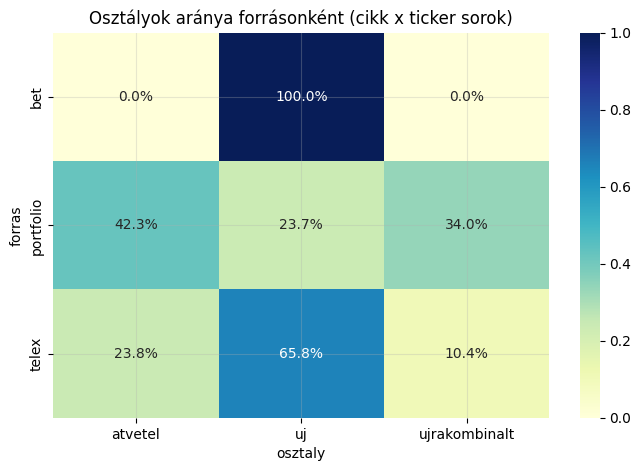

In [8]:
def osztaly_hoterkep(adat, cim):
    plt.figure(figsize=(8, 5))
    tabla = pd.crosstab(adat.forras, adat.osztaly, normalize="index")
    sns.heatmap(tabla, annot=True, cmap="YlGnBu", fmt=".1%")
    plt.title(cim)
    plt.show()


print("Osztály x forrás (cikk x ticker sorok):")
display(pd.crosstab(osztalyok.forras, osztalyok.osztaly, margins=True))

nem_bet = osztalyok[osztalyok.indok != "bet"]
print("\nIndok (nem-BÉT):", dict(Counter(nem_bet.indok)))

print("\nCsak a szövegből számolt osztályok (nem-BÉT):")
display(pd.crosstab(nem_bet.forras, nem_bet.osztaly_szoveg))

osztaly_hoterkep(osztalyok, "Osztályok aránya forrásonként (cikk x ticker sorok)")

**Amit ebből látok:** 7706 sor van, ebből 1345 BÉT-közlemény, és ezek a beállításom miatt mind újak. A Portfolio sorainak 42,3%-a átvétel, 34,0%-a újrakombinált, és csak 23,7%-a új. A Telexnél a sorok 65,8%-a új.

Ez a táblázat azért torzít, mert a több cégről szóló cikkek többször szerepelnek benne. Ezért a következő lépésben cikkszintre alakítom.

### 3.2 Cikk szinten

Ha egy cikk több cégről szól, az egyik cégnél lehet új, a másiknál átvétel. Ilyenkor egy sorrendet használok: **átvétel → újrakombinált → új**. Vagyis ha egy cikk bármelyik cégnél átvétel, akkor a cikket átvételnek tekintem. Ez egy döntés a részemről, ami a régi hírek arányát inkább felfelé tolja.

A `cikk_szintre` függvény a sorokat ebben a sorrendben rendezi, és cikkenként az első sort tartja meg. A függvényt a későbbi szakaszokban is használom.

Cikk x ticker sorok: 7706
Egyedi cikkek: 3713

Osztály x forrás (egyedi cikkek):


osztaly,atvetel,uj,ujrakombinalt,All
forras,,,,
bet,0,1345,0,1345
portfolio,969,583,590,2142
telex,57,144,25,226
All,1026,2072,615,3713



Indok (nem-BÉT cikkek): {'szoveg': 2011, 'hivatkozas': 155, 'szoveg+hivatkozas': 202}


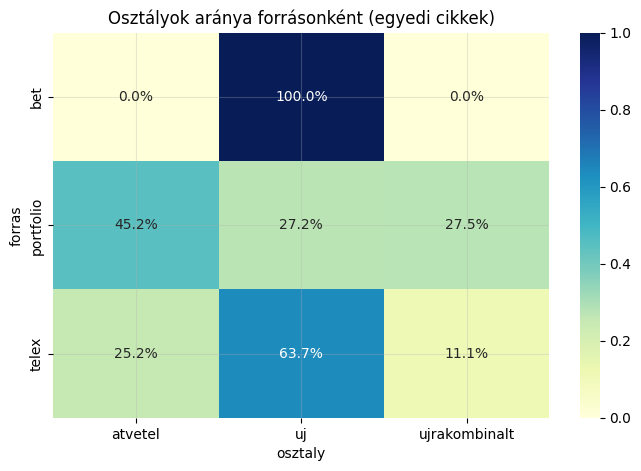

In [9]:
PRIORITAS = ["atvetel", "ujrakombinalt", "uj", "rovid"]


def cikk_szintre(tabla):
    tabla = tabla.copy()
    tabla["osztaly"] = pd.Categorical(tabla["osztaly"], categories=PRIORITAS, ordered=True)
    tabla = tabla.sort_values("osztaly", kind="stable")
    cikkek = tabla.drop_duplicates("doc_id").copy()
    cikkek["osztaly"] = cikkek["osztaly"].astype(str)
    return cikkek


cikkek = cikk_szintre(osztalyok)

print(f"Cikk x ticker sorok: {len(osztalyok)}")
print(f"Egyedi cikkek: {len(cikkek)}\n")

print("Osztály x forrás (egyedi cikkek):")
display(pd.crosstab(cikkek.forras, cikkek.osztaly, margins=True))

cikk_nem_bet = cikkek[cikkek.indok != "bet"]
print("\nIndok (nem-BÉT cikkek):", dict(Counter(cikk_nem_bet.indok)))

osztaly_hoterkep(cikkek, "Osztályok aránya forrásonként (egyedi cikkek)")

**Amit ebből látok:** a 7706 sorból 3713 egyedi cikk lett.

| Forrás | Átvétel | Újrakombinált | Új | Összesen |
|---|---|---|---|---|
| BÉT | 0 | 0 | 1345 | 1345 |
| Portfolio | 969 (45%) | 590 (28%) | 583 (27%) | 2142 |
| Telex | 57 (25%) | 25 (11%) | 144 (64%) | 226 |

A Portfolio cikkeinek csak 27%-a új, a Telexnél ez 64%. Ezt viszont óvatosan kezelem. A Portfolio sokkal több cikket ír, ezért egy cikknek sokkal több jelöltje van a 72 órás ablakban, és minél több a jelölt, annál nagyobb lesz az Old csak a közös szókincs miatt. A különbség tehát nem biztos, hogy csak a szerkesztőségi gyakorlatból jön. A 8. szakaszban meg is nézem, hogy az algoritmus egyáltalán jól méri-e a régi híreket.

In [10]:
kimaradt = meta[~meta.index.isin(cikkek.doc_id)]
print(f"Kimaradt dokumentumok száma: {len(kimaradt)}")
print(kimaradt.forras.value_counts())

Kimaradt dokumentumok száma: 317
forras
portfolio    224
telex         93
Name: count, dtype: int64


**Amit ebből látok:** 317 dokumentum kimaradt, mert egyik sem tartalmazza a négy vizsgált cég (OTP, MOL, Richter, Magyar Telekom) egyikét sem, ezért nincs hozzájuk ticker és nincs mivel összehasonlítani őket. Hogy ezek általános piaci vagy gazdasági hírek-e, azt külön nem vizsgáltam, ezért csak annyit állítok, hogy nem a vizsgált cégekről szólnak.

### 3.3 Az Old és a ClosestNeighbor eloszlása

A bal oldali ábra az Old értékeit mutatja forrásonként, a szaggatott vonal a 0,6-os küszöb. A jobb oldali ábra azokat a cikkeket mutatja, amelyeknél az Old legalább 0,6, és a ClosestNeighbor / Old arányt ábrázolja, a szaggatott vonal a 0,8-as küszöb.

In [20]:
def old_hisztogramok(adat, cim_vege):
    adat = adat[(adat.forras != "bet") & adat.regi_arany.notna()]
    regiek = adat[adat.regi_arany >= REGI_KUSZOB]

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    for forras, resz in adat.groupby("forras"):
        ax[0].hist(resz.regi_arany, bins=40, alpha=0.6, label=forras)
    ax[0].axvline(REGI_KUSZOB, color="k", ls="--")
    ax[0].set_title(f"Old eloszlása ({cim_vege})")
    ax[0].set_xlabel("Old")
    ax[0].legend()

    ax[1].hist(regiek.kozeli_arany / regiek.regi_arany, bins=40, color="C2")
    ax[1].axvline(REGI_ATVETEL_KUSZOB, color="k", ls="--")
    ax[1].set_title(f"ClosestNeighbor / Old ({cim_vege}, csak Old ≥ {REGI_KUSZOB})")

    plt.tight_layout()
    plt.show()



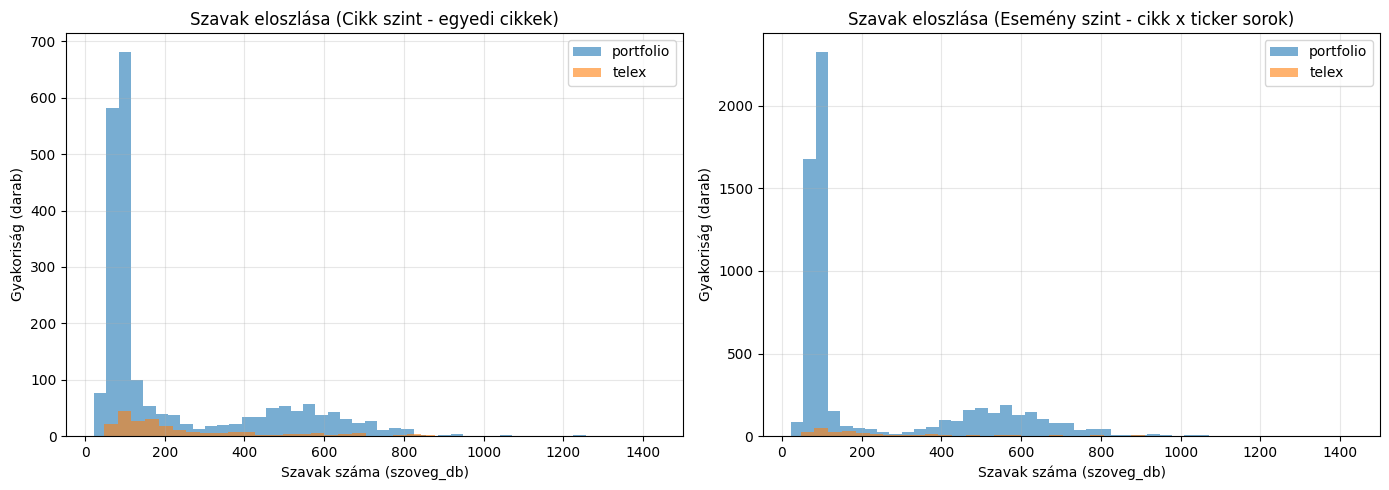

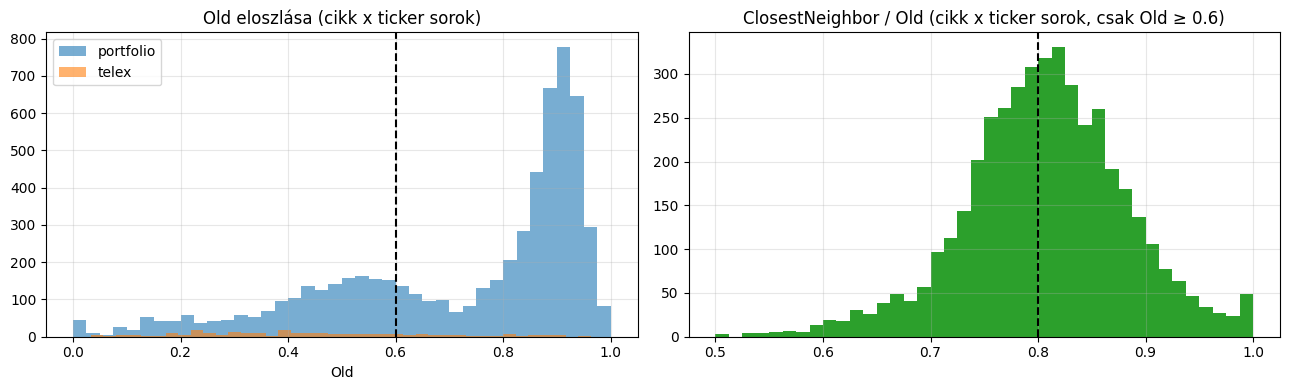

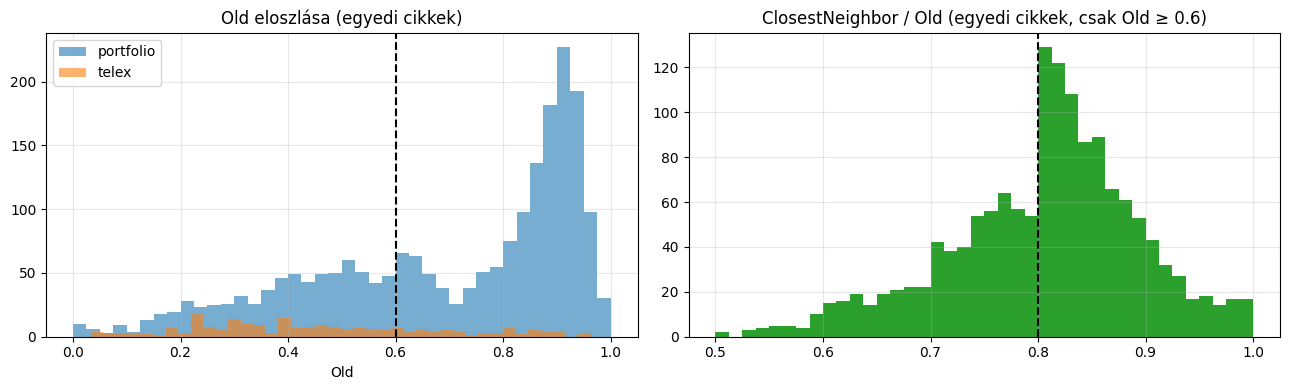

In [21]:
import matplotlib.pyplot as plt

def szavak_szama_hisztogramok_cikk_es_esemeny(cikkek_tabla, osztalyok_tabla):
    tisztitott_cikkek = cikkek_tabla[
        (cikkek_tabla["forras"] != "bet") & 
        (cikkek_tabla["regi_arany"].notna())
    ]
    
    tisztitott_osztalyok = osztalyok_tabla[
        (osztalyok_tabla["forras"] != "bet") & 
        (osztalyok_tabla["regi_arany"].notna())
    ]

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    for forras_nev, resz_tabla in tisztitott_cikkek.groupby("forras"):
        ax[0].hist(resz_tabla["szoveg_db"], bins=40, alpha=0.6, label=forras_nev)
        
    ax[0].set_title("Szavak eloszlása (Cikk szint - egyedi cikkek)")
    ax[0].set_xlabel("Szavak száma (szoveg_db)")
    ax[0].set_ylabel("Gyakoriság (darab)")
    ax[0].legend()

    for forras_nev, resz_tabla in tisztitott_osztalyok.groupby("forras"):
        ax[1].hist(resz_tabla["szoveg_db"], bins=40, alpha=0.6, label=forras_nev)
        
    ax[1].set_title("Szavak eloszlása (Esemény szint - cikk x ticker sorok)")
    ax[1].set_xlabel("Szavak száma (szoveg_db)")
    ax[1].set_ylabel("Gyakoriság (darab)")
    ax[1].legend()

    plt.tight_layout() 
    plt.show()

szavak_szama_hisztogramok_cikk_es_esemeny(cikkek, osztalyok)
old_hisztogramok(osztalyok, "cikk x ticker sorok")
old_hisztogramok(cikkek, "egyedi cikkek")

**Amit ebből látok:**

- A cikk × ticker ábrán a Portfolio Old-ja 0,9 felett kb. 800-as csúcsot mutat. Ez a több cégről szóló cikkek ismétlődése miatt van. Egyedi cikkekre ez kb. 230-ra csökken.
- A Portfolio eloszlása jobbra húz, a csúcs 0,9 és 1,0 között van. A Telex cikkei szétszórtabbak, sok van a 0,6-os küszöb alatt is, de nem mind: egy része az Old magas értékeinél is látszik.
- A ClosestNeighbor / Old eloszlás egy csúcsú, és a csúcs éppen a 0,8-as küszöbnél van. Ezért az átvétel és az újrakombinált közti határ nem természetes, a 0,8 egy önkényes vágás. Emiatt az átvétel és az újrakombinált megkülönböztetését nem tekintem megbízhatónak, a dolgozatban inkább csak a régi és az új közti különbséget használom.
- Nagyon érdekes egymás alatt megfigyelni a hisztogramokat, szinte egymás tökéletes tükörképei, a szavak hossza és az azonosított régi cikkek eloszlásának. Látható az ábrákon is, hogy a cikkek hossza erősen befolyásolja az algoritmus cimkéit. A módszer gyengepontja, hogy a hosszú cikkek rengeteg szót lefednek.

### 3.4 Az osztályok jellemzői

Megnézem osztályonként az átlagos Old és ClosestNeighbor értéket, a cikkek szótő-hosszát, és azt, hogy a hivatkozás-szabály hány sornál változtatta meg a szöveges osztályt. A nevezőben mindig a nem-BÉT sorok vannak.

In [22]:
for nev, adat in [("cikk x ticker sorok", osztalyok), ("egyedi cikkek", cikkek)]:
    nem_bet = adat[adat.indok != "bet"]

    print(f"--- {nev} ---")
    print("Átlagos hasonlóság osztályonként (nem-BÉT):")
    display(nem_bet.groupby("osztaly")[["regi_arany", "kozeli_arany"]].mean().round(3))

    print("Szóhossz (egyedi szótő) osztályonként:")
    display(adat.groupby("osztaly")["szoveg_db"].describe()[["count", "mean", "50%", "max"]].round(1))

    megvaltoztatott = nem_bet[nem_bet.osztaly != nem_bet.osztaly_szoveg]
    print(f"A hivatkozás-szabály {len(megvaltoztatott)} sornál változtatta meg a szöveges osztályt a {len(nem_bet)} nem-BÉT sorból ({len(megvaltoztatott) / len(nem_bet):.1%}).\n")

--- cikk x ticker sorok ---
Átlagos hasonlóság osztályonként (nem-BÉT):


,regi_arany,kozeli_arany
osztaly,,
atvetel,0.815,0.695
uj,0.393,0.311
ujrakombinalt,0.829,0.619


Szóhossz (egyedi szótő) osztályonként:


,count,mean,50%,max
osztaly,,,,
atvetel,2645.0,151.2,86.0,1045.0
uj,2962.0,408.7,171.0,14631.0
ujrakombinalt,2099.0,160.6,92.0,1045.0


A hivatkozás-szabály 402 sornál változtatta meg a szöveges osztályt a 6361 nem-BÉT sorból (6.3%).

--- egyedi cikkek ---
Átlagos hasonlóság osztályonként (nem-BÉT):


,regi_arany,kozeli_arany
osztaly,,
atvetel,0.801,0.683
uj,0.372,0.279
ujrakombinalt,0.802,0.580


Szóhossz (egyedi szótő) osztályonként:


,count,mean,50%,max
osztaly,,,,
atvetel,1026.0,155.9,87.0,1045.0
uj,2072.0,368.2,125.0,14631.0
ujrakombinalt,615.0,180.0,92.0,926.0


A hivatkozás-szabály 155 sornál változtatta meg a szöveges osztályt a 2368 nem-BÉT sorból (6.5%).



**Amit ebből látok:**

- A régi osztályok (átvétel, újrakombinált) cikkei rövidek: a mediánjuk kb. 87–92 szótő. Az új cikkeknél ez 125–171. A rövid cikkeket tehát könnyebb lefedni a korábbi cikkek szavaival, ez a 8. szakaszban fontos lesz.
- A hivatkozás-szabály a 6361 nem-BÉT cikk × ticker sorból 402-ben (6,3%) változtatta meg a szöveges osztályt, az egyedi cikkeknél a 2368-ból 155-ben (6,5%). Az arány a két szinten közel azonos.
- Az egyedi cikkeknél 2011 cikknél csak a szöveges hasonlóság döntött, 202 cikknél a szöveg és a hivatkozás is régit mondott, és 155 cikknél csak a hivatkozás tette régivé a cikket. Hogy a hivatkozás alapján régire jelölt cikkek valóban régiek-e, azt a 8.4 szakaszban ellenőrzöm a kézi címkékkel.

## 4. Érzékenységvizsgálat

A szakasz két részből áll. A 4.1 a paramétereket (időablak, küszöbök) változtatja, a 4.2 az algoritmus három módosítását próbálja ki. A 4.2 eredményeit a 8.10 szakasz veti össze a kézi címkékkel.

### 4.1 Paraméterrács

Az osztályozás három paramétertől függ: az időablaktól, az Old-küszöbtől és az átvétel-küszöbtől. Azt nézem meg, hogy ha ezeket változtatom, hogyan változik az osztályok aránya. Három időablakot (24, 72, 168 óra), öt Old-küszöböt és három átvétel-küszöböt próbálok ki, ez összesen 45 kombináció. Mindegyiknél újra lefuttatom az osztályozást, és csak a nem-BÉT cikkeket számolom egyedi cikkekként.

Ez a cella hosszabb ideig is futhat.

In [24]:
def parameter_racs(ablakok, kuszobok, atvetel_kuszobok):
    sorok = []
    for ablak in ablakok:
        for kuszob in kuszobok:
            for atvetel_kuszob in atvetel_kuszobok:
                valtozat = pd.DataFrame(osztalyoz(dokok, forras_link, kulso, ablak, kuszob, atvetel_kuszob))
                valtozat_cikkek = cikk_szintre(valtozat)
                valtozat_cikkek = valtozat_cikkek[valtozat_cikkek.indok != "bet"]

                darabok = valtozat_cikkek["osztaly"].value_counts().to_dict()
                osszes = len(valtozat_cikkek)
                uj_db = darabok.get("uj", 0)
                atvetel_db = darabok.get("atvetel", 0)
                ujrakomb_db = darabok.get("ujrakombinalt", 0)

                sorok.append({
                    "Ablak_h": ablak,
                    "Old_Küszöb": kuszob,
                    "Átvétel_Küszöb": atvetel_kuszob,
                    "Új_Arány_%": round(uj_db / osszes * 100, 1),
                    "Régi_Arány_%": round((atvetel_db + ujrakomb_db) / osszes * 100, 1),
                    "Új_db": uj_db,
                    "Átvétel_db": atvetel_db,
                    "Újrakombinált_db": ujrakomb_db,
                    "Összes_cikk_db": osszes
                })
    return pd.DataFrame(sorok)


racs_df = parameter_racs([24, 72, 168], [0.4, 0.5, 0.6, 0.7, 0.75], [0.7, 0.8, 0.9])
racs_df = racs_df.sort_values(by="Új_Arány_%", ascending=False).reset_index(drop=True)
print(f"{len(racs_df)} paraméter-kombináció")
display(racs_df.head(10))

45 paraméter-kombináció


,Ablak_h,Old_Küszöb,Átvétel_Küszöb,Új_Arány_%,Régi_Arány_%,Új_db,Átvétel_db,Újrakombinált_db,Összes_cikk_db
0,24,0.75,0.7,50.8,49.2,1203,1061,104,2368
1,24,0.75,0.9,50.8,49.2,1203,390,775,2368
2,24,0.75,0.8,50.8,49.2,1203,782,383,2368
3,24,0.70,0.8,47.7,52.3,1129,854,385,2368
4,24,0.70,0.7,47.7,52.3,1129,1140,99,2368
5,24,0.70,0.9,47.7,52.3,1129,434,805,2368
6,24,0.60,0.9,43.1,56.9,1021,539,808,2368
7,24,0.60,0.7,43.1,56.9,1021,1244,103,2368
8,24,0.60,0.8,43.1,56.9,1021,964,383,2368
9,72,0.75,0.7,40.6,59.4,962,1302,104,2368


A táblázat az új cikkek aránya szerint csökkenő sorrendben van, az első 10 sort mutatja. A 72 órás ablaknál az osztályok megoszlását ábrán is megnézem:

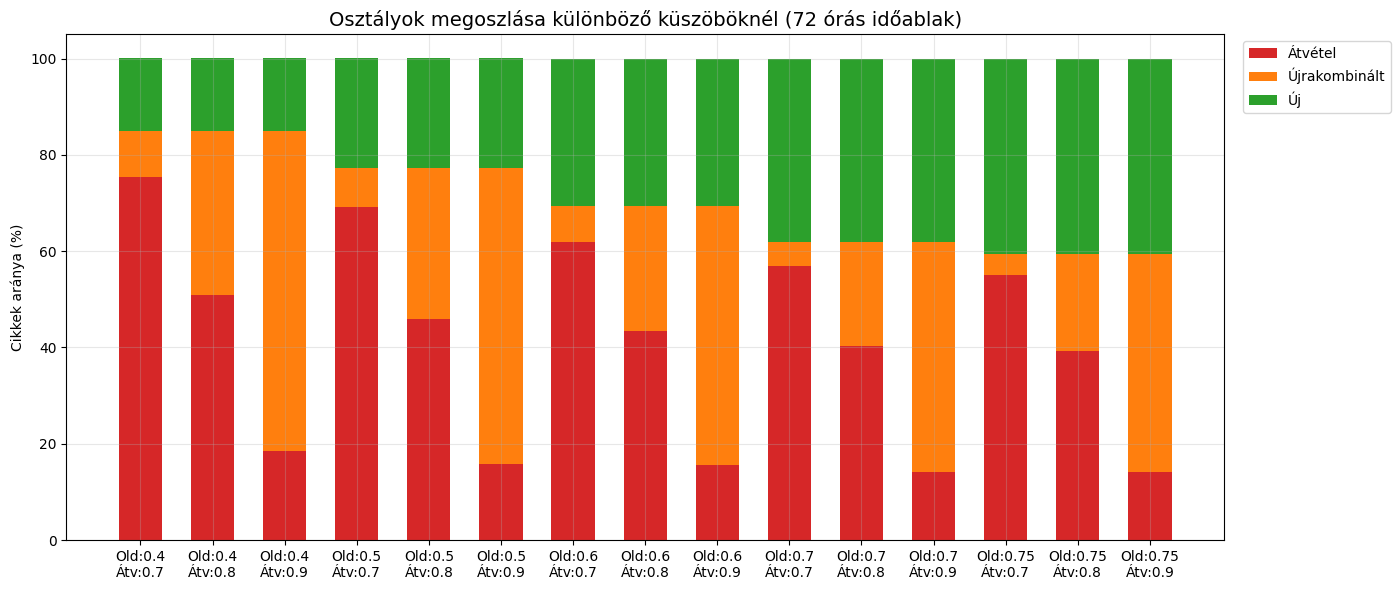

In [25]:
alap_adat = racs_df[racs_df["Ablak_h"] == REGI_ABLAK_ORA].copy()
alap_adat["Átvétel_%"] = alap_adat["Átvétel_db"] / alap_adat["Összes_cikk_db"] * 100
alap_adat["Újrakombinált_%"] = alap_adat["Újrakombinált_db"] / alap_adat["Összes_cikk_db"] * 100
alap_adat["Kombináció"] = "Old:" + alap_adat["Old_Küszöb"].astype(str) + "\nÁtv:" + alap_adat["Átvétel_Küszöb"].astype(str)
alap_adat = alap_adat.sort_values(["Old_Küszöb", "Átvétel_Küszöb"])

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(alap_adat))
szelesseg = 0.6

ax.bar(x, alap_adat["Átvétel_%"], szelesseg, label="Átvétel", color="C3")
ax.bar(x, alap_adat["Újrakombinált_%"], szelesseg, bottom=alap_adat["Átvétel_%"], label="Újrakombinált", color="C1")
ax.bar(x, alap_adat["Új_Arány_%"], szelesseg, bottom=alap_adat["Átvétel_%"] + alap_adat["Újrakombinált_%"], label="Új", color="C2")

ax.set_xticks(x)
ax.set_xticklabels(alap_adat["Kombináció"])
ax.set_ylabel("Cikkek aránya (%)")
ax.set_title(f"Osztályok megoszlása különböző küszöböknél ({REGI_ABLAK_ORA} órás időablak)", fontsize=14)
ax.legend(loc="upper right", bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.show()

**Amit ebből látok:**

- **Az Old-küszöb a régi és az új közti határt mozgatja.** Minél alacsonyabb a küszöb, annál több cikk számít réginek. A 72 órás ablaknál 0,4-es küszöbnél az új cikkek aránya kb. 15%, 0,75-nél kb. 40%.
- **Az átvétel-küszöb csak a régi cikkek felosztását változtatja**, az új cikkek számát nem. Ez a kódból következik, nem külön eredmény.
- **Az időablak is sokat számít.** A legszigorúbb sarokban (24 óra, 0,75-ös Old-küszöb) a régi cikkek aránya 49,2%, vagyis 50% alá esik. Az alap beállításnál (72 óra, 0,6 és 0,8) a nem-BÉT cikkek 43%-a átvétel, 26%-a újrakombinált és 31%-a új, a régi arány tehát kb. 69%.
- Az osztályozás ezért erősen függ a paraméterektől, és az algoritmus alapján a „többség régi" állítás is a beállítástól függ. Hogy melyik beállítás helyes, azt a kézi címkékkel tudom eldönteni, ezt a 8. szakaszban vizsgálom.

### 4.2 Javítási próbák

Három módosítást próbálok ki az algoritmuson. Mindegyiknél azt nézem, hogyan változik a régi hírek aránya.

| Próba | Mit változtat | Miért |
|---|---|---|
| **Számok egyben** | A `84,6` és a `16 919` egy szó marad, nem esik szét `84`, `6` és `16`, `919` részekre. | A szétesett apró számok (`5`, `6`, `7`) „közös szónak" számítottak szinte bármelyik két cikk között. |
| **Általános szavak kiszűrése** | Kidobom azokat a szavakat, amelyek a dokumentumok legalább 10%-ában előfordulnak (pl. `részvény`, `magyar`, `otp`, `ba`). | Ezek nem a hírre jellemzők, mégis „lefednek" bármilyen cikket. |
| **Csak erős tickeres jelöltek** | Egy korábbi cikk csak akkor lehet jelölt, ha a cég a címében vagy leadjében szerepel (`ticker_eros`), nem csak a szövegben. | Ha egy hosszú piaci összefoglaló csak egyszer említi a céget, nem ugyanarról a hírről szól. |

Ezen kívül azt is megnézem, mi történik, ha az elemzés **csak az erős tickeres cikk × ticker párokat** vizsgálja (a cikk és a jelöltek is csak erős tickeresek).

Az algoritmus maga (jelöltek, Old, ClosestNeighbor, küszöbök, hivatkozás-szabály) ugyanaz marad. Az 1. szakasz függvényeit használom tovább (`meres`, `osztaly_dont`, `ticker_listak`, `jeloltek_valasztas`, `hivatkozott_korabbiak`, `cikk_szintre`), csak a szóhalmazokat és a tickereket cserélem ki. Az 1. szakasz adatai (`dokok`) közben változatlanok maradnak, mert a későbbi szakaszok is használják őket.

A kézi címkékkel való összevetés a 8.10 szakaszban van, mert a kézi minta csak a 6–7. szakaszban készül el.

#### Számok egyesítése

A `szotovek_szamjavitva` ugyanazt csinálja, mint a `szotovek`, de előtte egy szóvá egyesíti a tizedes számokat (`84,6` → `84.6`) és a szóközzel tagolt számokat (`16 919` → `16919`). A szóközös szám csak akkor egyesül, ha az első csoport 1–3 jegyű, a következők pontosan 3 jegyűek. Így a `2024 150 forintos` nem lesz `2024150`.

In [26]:
JAV_TOKEN = re.compile(r"\d+(?:\.\d+)?|[^\W_]+")
JAV_SZAM = re.compile(r"\d+(?:\.\d+)?")
JAV_EZRES = re.compile(r"\b\d{1,3}(?:[ \u00a0]\d{3})+\b")


def ezres_egyesit(talalat):
    return re.sub(r"[ \u00a0]", "", talalat.group(0))


def szamok_egyesit(szoveg):
    szoveg = JAV_EZRES.sub(ezres_egyesit, szoveg)
    return re.sub(r"(?<=\d),(?=\d)", ".", szoveg)


def szotovek_szamjavitva(szoveg):
    szavak = set()
    if szoveg is None:
        szoveg = ""
    for t in JAV_TOKEN.findall(szamok_egyesit(szoveg).lower()):
        if t in STOPSZAVAK:
            continue
        if JAV_SZAM.fullmatch(t):
            szavak.add(t)
            continue
        if len(t) < 2:
            continue
        if t in TICKER_SZAVAK:
            szavak.add(t)
            continue
        if t not in TOVEK_CACHE:
            TOVEK_CACHE[t] = TOVEZO.stemWord(t)
        szavak.add(TOVEK_CACHE[t])
    return frozenset(szavak)


pelda = "A tranzakció 16 919 forint/darab átlagáron, összesen 84,6 millió forint értékben történt, 7,5 százalékos plusszal."
print("régi :", sorted(szotovek(pelda)))
print("új   :", sorted(szotovek_szamjavitva(pelda)))

régi : ['16', '5', '6', '7', '84', '919', 'darab', 'forin', 'millió', 'plusz', 'százalékos', 'tranzakció', 'tört', 'átlagár', 'érte', 'összes']
új   : ['16919', '7.5', '84.6', 'darab', 'forin', 'millió', 'plusz', 'százalékos', 'tranzakció', 'tört', 'átlagár', 'érte', 'összes']


A szóhalmazokat minden dokumentumhoz újra elkészítem az adatbázisból: a régi módon (`eredeti`, ez a `dokok` szóhalmaza) és a számok egyesítésével (`szamjavitott`). A `javitas_eros` az erős tickereket tartalmazza, a `dokok` tickerei az erős és gyenge tickerek együtt.

In [27]:
javitas_szavak = {"eredeti": {}, "szamjavitott": {}}
javitas_eros = {}

con = db_ro()
for sor in con.execute(lekerdezes_dokok):
    if sor["forras"] == "bet":
        torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"])
    else:
        torzs = sor["szoveg"] or ""
    teljes_szoveg = f"{sor['cim'] or ''} {sor['lead'] or ''} {torzs}"

    javitas_szavak["eredeti"][sor["doc_id"]] = dokok[sor["doc_id"]].szavak
    javitas_szavak["szamjavitott"][sor["doc_id"]] = szotovek_szamjavitva(teljes_szoveg)
    javitas_eros[sor["doc_id"]] = sorted(set(json.loads(sor["ticker_eros"] or "[]")))
con.close()

print(f"{len(javitas_eros)} dokumentum")

4030 dokumentum


#### Általános szavak

Egy szó akkor általános, ha a dokumentumok legalább 10%-ában előfordul. A számolást a számegyesített szóhalmazokon végzem. Az `altalanos_szavak` megadja a kidobandó szavak halmazát egy adott határnál, a `szures` pedig kiveszi őket a szóhalmazokból.

In [28]:
javitas_df = Counter()
for szavak in javitas_szavak["szamjavitott"].values():
    javitas_df.update(szavak)


def altalanos_szavak(hatar):
    kidobott = set()
    for szo, db in javitas_df.items():
        if db / len(dokok) >= hatar:
            kidobott.add(szo)
    return kidobott


def szures(szavak_dict, kidobott):
    szurt = {}
    for doc_id, szavak in szavak_dict.items():
        szurt[doc_id] = szavak - kidobott
    return szurt


kidobott_10 = altalanos_szavak(0.10)
print(f"Általános szavak száma 10%-os határnál: {len(kidobott_10)} (az összes különböző szó {len(javitas_df)})")

leggyakoribbak = pd.DataFrame(javitas_df.most_common(40), columns=["szó", "dokumentumok_száma"])
leggyakoribbak["dokumentumok_%"] = (leggyakoribbak["dokumentumok_száma"] / len(dokok) * 100).round(1)
display(leggyakoribbak.T)

szurt_10 = szures(javitas_szavak["szamjavitott"], kidobott_10)
hossz_elotte = []
hossz_utana = []
for doc_id, d in dokok.items():
    if d.forras != "bet":
        hossz_elotte.append(len(javitas_szavak["szamjavitott"][doc_id]))
        hossz_utana.append(len(szurt_10[doc_id]))
print(f"\nNem-BÉT dokumentumok szóhossza (medián): {pd.Series(hossz_elotte).median():.0f} -> {pd.Series(hossz_utana).median():.0f}")

Általános szavak száma 10%-os határnál: 441 (az összes különböző szó 126408)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39
szó,otp,részvény,magyar,nap,áll,jelenleg,piac,eset,mol,forin,százale,ba,árfolyam,ma,alap,...,telekom,20,milliár,több,vállal,bux,chip,blu,nyrt,4,míg,jó,hangul,társaság,50
dokumentumok_száma,2847,2738,2736,2178,2064,2036,1987,1941,1936,1922,1902,1843,1832,1829,1811,...,1581,1567,1515,1505,1499,1481,1469,1465,1460,1455,1438,1400,1395,1375,1374
dokumentumok_%,70.6,67.9,67.9,54.0,51.2,50.5,49.3,48.2,48.0,47.7,47.2,45.7,45.5,45.4,44.9,...,39.2,38.9,37.6,37.3,37.2,36.7,36.5,36.4,36.2,36.1,35.7,34.7,34.6,34.1,34.1



Nem-BÉT dokumentumok szóhossza (medián): 101 -> 55


#### Az algoritmus futtatása változatokkal

A `DokNezet` egy dokumentum másolata, amelyben a szóhalmaz és a tickerek az adott változat szerint vannak beállítva. A `javitas_osztalyoz` ugyanazt a sorrendet követi, mint az 1. szakasz `osztalyoz` függvénye. Egyetlen új lépése: ha `csak_eros_jelolt` igaz, a jelöltek közül kiszűri azokat, amelyeknél a vizsgált cég nem erős ticker.

| # | Név | Szavak | Tickerek | Jelöltek |
|---|---|---|---|---|
| 1 | Eredeti | régi módon | erős + gyenge | bármelyik |
| 2 | + Számok egyben | számegyesített | erős + gyenge | bármelyik |
| 3 | + Általános szavak szűrve | számegyesített, szűrt | erős + gyenge | bármelyik |
| 4 | + Csak erős tickeres jelöltek | számegyesített, szűrt | erős + gyenge | csak erős tickeres |
| 5 | Csak erős tickeres párok, mind a három javítással | számegyesített, szűrt | csak erős | csak erős tickeres |
| 6 | Csak erős tickeres párok, eredeti szavakkal | régi módon | csak erős | csak erős tickeres |

Az 1. változatnak pontosan az 1. szakasz eredményét kell adnia, ezt ellenőrzöm.

In [29]:
class DokNezet:
    def __init__(self, d, szavak, tickerek, tickerek_eros):
        self.doc_id = d.doc_id
        self.forras = d.forras
        self.ts = d.ts
        self.kulcs = d.kulcs
        self.szavak = szavak
        self.tickerek = tickerek
        self.tickerek_eros = tickerek_eros


def nezetek_keszit(szavak_dict, parok):
    nezetek = {}
    for doc_id, d in dokok.items():
        if parok == "eros":
            tickerek = javitas_eros[doc_id]
        else:
            tickerek = d.tickerek
        nezetek[doc_id] = DokNezet(d, szavak_dict[doc_id], tickerek, javitas_eros[doc_id])
    return nezetek


def javitas_osztalyoz(nezetek, csak_eros_jelolt):
    ticker_dokok_v = ticker_listak(nezetek)
    sorok = []

    for ticker, lista in ticker_dokok_v.items():
        idok = []
        for d in lista:
            idok.append(d.ts)

        for i, s in enumerate(lista):
            sor = {
                "doc_id": s.doc_id,
                "forras": s.forras,
                "ticker": ticker,
                "szoveg_db": len(s.szavak),
                "regi_arany": None,
                "kozeli_arany": None,
                "jelolt_db": 0,
            }

            if s.forras == "bet":
                sor["osztaly"] = "uj"
                sor["osztaly_szoveg"] = "uj"
                sor["indok"] = "bet"
                sorok.append(sor)
                continue

            jeloltek = jeloltek_valasztas(lista, idok, i)
            if csak_eros_jelolt:
                erosek = []
                for c in jeloltek:
                    if ticker in c.tickerek_eros:
                        erosek.append(c)
                jeloltek = erosek
            sor["jelolt_db"] = len(jeloltek)

            if len(s.szavak) < REGI_MIN_SZO:
                sor["osztaly"] = "rovid"
                sor["osztaly_szoveg"] = "rovid"
                sor["indok"] = "szoveg"
                sorok.append(sor)
                continue

            old, kozeli, szomszedok = meres(s, jeloltek, REGI_SZOMSZED_DB)
            osztaly_szoveg = osztaly_dont(old, kozeli, REGI_KUSZOB, REGI_ATVETEL_KUSZOB)
            osztaly = osztaly_szoveg
            indok = "szoveg"

            korabbiak = hivatkozott_korabbiak(s, nezetek, forras_link)
            if len(korabbiak) > 0:
                if osztaly_szoveg == "uj":
                    if len(korabbiak) == 1:
                        osztaly = "atvetel"
                    else:
                        osztaly = "ujrakombinalt"
                    indok = "hivatkozas"
                else:
                    indok = "szoveg+hivatkozas"

            sor["osztaly"] = osztaly
            sor["osztaly_szoveg"] = osztaly_szoveg
            sor["regi_arany"] = old
            sor["kozeli_arany"] = kozeli
            sor["indok"] = indok
            sorok.append(sor)

    return sorok


def javitas_futtat(beallitas):
    szavak_dict = javitas_szavak[beallitas["szavak"]]
    if beallitas["hatar"] is not None:
        szavak_dict = szures(szavak_dict, altalanos_szavak(beallitas["hatar"]))
    nezetek = nezetek_keszit(szavak_dict, beallitas["parok"])
    return pd.DataFrame(javitas_osztalyoz(nezetek, beallitas["csak_eros_jelolt"]))


JAVITAS_VALTOZATOK = {
    "1 Eredeti": {"szavak": "eredeti", "hatar": None, "parok": "mind", "csak_eros_jelolt": False},
    "2 + Számok egyben": {"szavak": "szamjavitott", "hatar": None, "parok": "mind", "csak_eros_jelolt": False},
    "3 + Általános szavak szűrve": {"szavak": "szamjavitott", "hatar": 0.10, "parok": "mind", "csak_eros_jelolt": False},
    "4 + Csak erős tickeres jelöltek": {"szavak": "szamjavitott", "hatar": 0.10, "parok": "mind", "csak_eros_jelolt": True},
    "5 Csak erős párok (3 javítással)": {"szavak": "szamjavitott", "hatar": 0.10, "parok": "eros", "csak_eros_jelolt": True},
    "6 Csak erős párok (eredeti szavak)": {"szavak": "eredeti", "hatar": None, "parok": "eros", "csak_eros_jelolt": True},
}

javitas_sorok = {}
javitas_cikkek = {}

for nev, beallitas in JAVITAS_VALTOZATOK.items():
    sorok_v = javitas_futtat(beallitas)
    javitas_sorok[nev] = sorok_v

    cikkek_v = cikk_szintre(sorok_v)
    javitas_cikkek[nev] = cikkek_v[cikkek_v.indok != "bet"]
    print(nev, "->", len(sorok_v), "cikk x ticker sor,", len(javitas_cikkek[nev]), "nem-BÉT cikk")

ellenorzes = javitas_cikkek["1 Eredeti"].osztaly.value_counts()
print("\nAz 1. változat nem-BÉT cikkei:", dict(ellenorzes))
print("Az 1. szakasz egyedi cikkei (nem-BÉT):", dict(cikkek[cikkek.indok != "bet"].osztaly.value_counts()))

1 Eredeti -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk
2 + Számok egyben -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk
3 + Általános szavak szűrve -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk
4 + Csak erős tickeres jelöltek -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk
5 Csak erős párok (3 javítással) -> 3153 cikk x ticker sor, 1530 nem-BÉT cikk
6 Csak erős párok (eredeti szavak) -> 3153 cikk x ticker sor, 1530 nem-BÉT cikk

Az 1. változat nem-BÉT cikkei: {'atvetel': np.int64(1026), 'uj': np.int64(727), 'ujrakombinalt': np.int64(615)}
Az 1. szakasz egyedi cikkei (nem-BÉT): {'atvetel': np.int64(1026), 'uj': np.int64(727), 'ujrakombinalt': np.int64(615)}


2 + Számok egyben -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk


3 + Általános szavak szűrve -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk


4 + Csak erős tickeres jelöltek -> 7706 cikk x ticker sor, 2368 nem-BÉT cikk


5 Csak erős párok (3 javítással) -> 3153 cikk x ticker sor, 1530 nem-BÉT cikk
6 Csak erős párok (eredeti szavak) -> 3153 cikk x ticker sor, 1530 nem-BÉT cikk

Az 1. változat nem-BÉT cikkei: {'atvetel': np.int64(1026), 'uj': np.int64(727), 'ujrakombinalt': np.int64(615)}
Az 1. szakasz egyedi cikkei (nem-BÉT): {'atvetel': np.int64(1026), 'uj': np.int64(727), 'ujrakombinalt': np.int64(615)}


#### Eredmény

A **Régi arány** a régi hírek (átvétel + újrakombinált) aránya a **nem rövid** nem-BÉT cikkek között. A `rövid` oszlop azt mutatja, hány cikk lett 10 szónál rövidebb (ezeket nem osztályozom, és az arányból kihagyom). A szűrt szavaknál ez megnőhet.

,cikk,rövid,új,átvétel,újrakombinált,Régi arány %,Átlag Old,Régi arány % (portfolio),Régi arány % (telex)
változat,,,,,,,,,
1 Eredeti,2368,0,727,1026,615,69.3,0.669,72.8,36.3
2 + Számok egyben,2368,0,759,960,649,67.9,0.651,71.3,35.8
3 + Általános szavak szűrve,2368,147,1484,372,365,33.2,0.382,33.9,26.5
4 + Csak erős tickeres jelöltek,2368,147,1707,373,141,23.1,0.238,22.9,25.7
5 Csak erős párok (3 javítással),1530,78,1086,285,81,25.2,0.261,24.8,27.9
6 Csak erős párok (eredeti szavak),1530,0,737,539,254,51.8,0.494,54.5,33.5


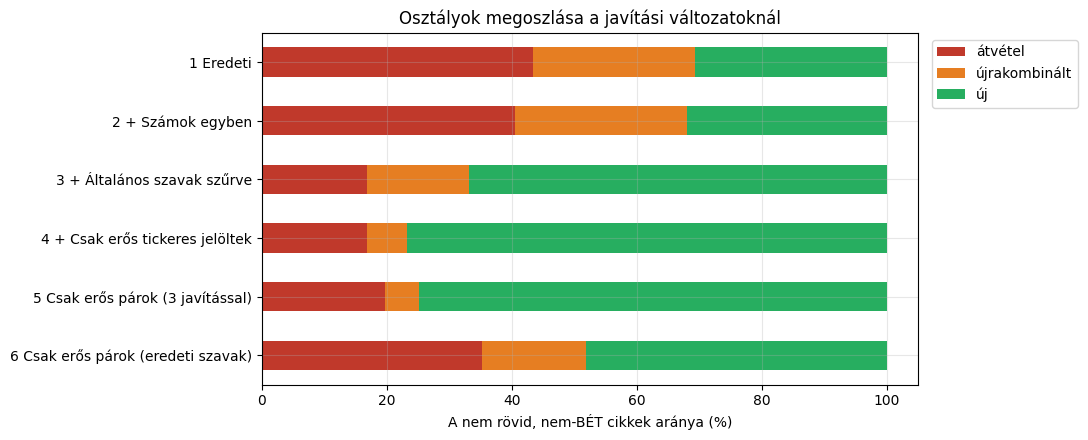

In [30]:
def javitas_eredmeny_sor(nev, cikkek_v):
    darab = cikkek_v.osztaly.value_counts()
    uj = darab.get("uj", 0)
    atvetel = darab.get("atvetel", 0)
    ujrakomb = darab.get("ujrakombinalt", 0)
    rovid = darab.get("rovid", 0)
    osztalyozott = uj + atvetel + ujrakomb

    sor = {
        "változat": nev,
        "cikk": len(cikkek_v),
        "rövid": rovid,
        "új": uj,
        "átvétel": atvetel,
        "újrakombinált": ujrakomb,
        "Régi arány %": round((atvetel + ujrakomb) / osztalyozott * 100, 1),
        "Átlag Old": round(cikkek_v.regi_arany.mean(), 3),
    }

    for forras in ["portfolio", "telex"]:
        resz = cikkek_v[(cikkek_v.forras == forras) & (cikkek_v.osztaly != "rovid")]
        regi_db = resz.osztaly.isin(["atvetel", "ujrakombinalt"]).sum()
        sor[f"Régi arány % ({forras})"] = round(regi_db / len(resz) * 100, 1)
    return sor


javitas_eredmenyek = []
for nev, cikkek_v in javitas_cikkek.items():
    javitas_eredmenyek.append(javitas_eredmeny_sor(nev, cikkek_v))
javitas_tabla = pd.DataFrame(javitas_eredmenyek).set_index("változat")
display(javitas_tabla)

arany_tabla = javitas_tabla[["új", "átvétel", "újrakombinált"]]
szazalek = arany_tabla.div(arany_tabla.sum(axis=1), axis=0) * 100

abra = szazalek[["átvétel", "újrakombinált", "új"]].plot(
    kind="barh", stacked=True, figsize=(11, 4.5), color=["#c0392b", "#e67e22", "#27ae60"]
)
abra.invert_yaxis()
abra.set_xlabel("A nem rövid, nem-BÉT cikkek aránya (%)")
abra.set_ylabel("")
abra.set_title("Osztályok megoszlása a javítási változatoknál")
abra.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Az 5. és 6. változat kevesebb cikket vizsgál (csak azokat, amelyeknek van erős tickerük), ezért a számaik nem közvetlenül összevethetők az 1–4. változatokkal. Itt minden változatot ugyanarra a cikkhalmazra szűkítek: azokra, amelyeket az 5. változat is vizsgál.

In [31]:
kozos_cikkek = set(javitas_cikkek["5 Csak erős párok (3 javítással)"].doc_id)

javitas_azonos = []
for nev, cikkek_v in javitas_cikkek.items():
    resz = cikkek_v[cikkek_v.doc_id.isin(kozos_cikkek)]
    javitas_azonos.append(javitas_eredmeny_sor(nev, resz))

print(f"Közös cikkhalmaz: {len(kozos_cikkek)} cikk")
display(pd.DataFrame(javitas_azonos).set_index("változat"))

Közös cikkhalmaz: 1530 cikk


,cikk,rövid,új,átvétel,újrakombinált,Régi arány %,Átlag Old,Régi arány % (portfolio),Régi arány % (telex)
változat,,,,,,,,,
1 Eredeti,1530,0,492,638,400,67.8,0.665,72.2,38.6
2 + Számok egyben,1530,0,502,601,427,67.2,0.644,71.5,38.1
3 + Általános szavak szűrve,1530,78,928,285,239,36.1,0.392,37.2,28.9
4 + Csak erős tickeres jelöltek,1530,78,1054,293,105,27.4,0.274,27.3,27.9
5 Csak erős párok (3 javítással),1530,78,1086,285,81,25.2,0.261,24.8,27.9
6 Csak erős párok (eredeti szavak),1530,0,737,539,254,51.8,0.494,54.5,33.5


#### Mennyire függ az eredmény a 10%-os szűrőtől?

A 10% választás volt. Itt a 4. változatot futtatom különböző határokkal. Minél magasabb a határ, annál kevesebb szót dobok ki. A „nincs szűrés" sor az a 4. változat, amelyben az általános szavakat nem dobom ki, csak a számok vannak egyesítve és csak erős tickeres jelöltek számítanak.

In [32]:
javitas_hatar_sorok = {}
hatar_eredmenyek = []

for hatar in [0.05, 0.10, 0.20, 0.30, 0.50, None]:
    if hatar is None:
        nev = "nincs szűrés"
        kidobott_db = 0
    else:
        nev = f"határ {hatar:.0%}"
        kidobott_db = len(altalanos_szavak(hatar))

    beallitas = {"szavak": "szamjavitott", "hatar": hatar, "parok": "mind", "csak_eros_jelolt": True}
    sorok_h = javitas_futtat(beallitas)
    javitas_hatar_sorok[nev] = sorok_h

    cikkek_h = cikk_szintre(sorok_h)
    cikkek_h = cikkek_h[cikkek_h.indok != "bet"]
    sor = javitas_eredmeny_sor(nev, cikkek_h)
    sor["kidobott szó"] = kidobott_db
    hatar_eredmenyek.append(sor)

hatar_tabla = pd.DataFrame(hatar_eredmenyek).set_index("változat")
display(hatar_tabla[["kidobott szó", "cikk", "rövid", "új", "átvétel", "újrakombinált", "Régi arány %", "Átlag Old"]])

,kidobott szó,cikk,rövid,új,átvétel,újrakombinált,Régi arány %,Átlag Old
változat,,,,,,,,
határ 5%,977,2368,913,1093,302,60,24.9,0.172
határ 10%,441,2368,147,1707,373,141,23.1,0.238
határ 20%,149,2368,0,1586,426,356,33.0,0.333
határ 30%,65,2368,0,1327,610,431,44.0,0.401
határ 50%,6,2368,0,1094,968,306,53.8,0.473
nincs szűrés,0,2368,0,1055,1048,265,55.4,0.487


**Amit ebből látok:** a nem-BÉT cikkek régi aránya az 1. szakasz beállításával 69,3%. A számok egyesítése ezt alig változtatja (67,9%). Az általános szavak kiszűrése 33,2%-ra viszi le, a csak erős tickeres jelöltek szabálya 23,1%-ra. Csak erős tickeres párokkal és az eredeti szavakkal 51,8% jön ki (1530 cikk).

Az általános szavak szűrése a legnagyobb hatású, de a határtól erősen függ. 10%-os határnál 147 cikk 10 szónál rövidebbé válik (ezeket nem osztályozom), 5%-os határnál már 913. A régi arány a határtól függően 25% és 55% között mozog. Hogy melyik beállítás találja el a kézi címkéket, azt a 8.10 szakasz dönti el. Ott az derül ki, hogy egyik változat sem egyezik jobban a kézi címkékkel, mint az eredeti.

## 5. Mentés

A `03_esemenyek` notebook ezt a táblát olvassa. Az alap paraméterekkel készült `osztalyok` táblát mentem el, cikk × ticker szinten.

Fontos, hogy a 8. szakasz szerint ezek az algoritmusos osztályok a kézi címkékkel csak gyengén egyeznek. Ezt a következő notebookban figyelembe kell venni.

In [33]:
osztalyok.to_parquet(CACHE / "regi_hir.parquet", index=False)
print("Elmentve:", CACHE / "regi_hir.parquet")

Elmentve: C:\Users\User\Desktop\BGE Szakdolgozat\adat\cache\regi_hir.parquet


## 6. H1a: a minta és a kézi validációs munkafüzet

**H1a:** A vizsgált újságírói portálok cikkeinek többsége régi hír

**H0:** a régi hírek aránya legfeljebb 50%. **H1:** a régi hírek aránya nagyobb 50%-nál.

Egymintás, jobb oldali aránypróbát használok, rétegzett véletlen mintán, a rétegek a portálok. A BÉT-közleményeket nem veszem bele, mert azok elsődleges források, és a beállításom szerint mindig újak.

A próbát nem az algoritmus címkéivel végzem, hanem kézzel címkézett mintával. A menete:

1. kihúzom a mintát, és létrehozok egy Excel munkafüzetet a címkézéshez,
2. kézzel megcímkézem a cikkeket,
3. beolvasom a címkéket, és elvégzem a próbát.

A kézi címkézés úgy működik, hogy egy cikk csak a nála korábbi, ugyanarról a cégről szóló cikkekhez képest lehet régi. Ezért a munkafüzet `ablak` lapján a minta minden cikkéhez ott van az időablak összes korábbi cikke url-lel együtt, nem csak azok, amelyek a mintába kerültek.

### 6.1 Beállítások

In [35]:
P0 = 0.50
ALFA = 0.05
N_MINTA = 400
SEED = 42
FPC_HATAR = 0.05
VALIDACIOS_FAJL = CACHE / "h1a_validacio.xlsx"

### 6.2 Alapsokaság és mintavétel

Az alapsokaság a Portfolio és a Telex cikk × ticker sorai (a `rovid` sorok nélkül). A mintát arányosan osztom el a két réteg között, rétegenként egyszerű véletlen mintavétellel, visszatevés nélkül. Utána ellenőrzöm az arányteszt feltételeit.

A `regi_alg` oszlop az algoritmus tippje: 1, ha átvétel vagy újrakombinált, 0, ha új.

In [36]:
alapsokasag = osztalyok[(osztalyok.osztaly != "rovid") & (osztalyok.forras != "bet")].copy()
alapsokasag["regi_alg"] = alapsokasag.osztaly.isin(["atvetel", "ujrakombinalt"]).astype(int)

N_h = alapsokasag.groupby("forras").size()
N = N_h.sum()
print("Alapsokaság rétegenként:", N_h.to_dict(), "| összesen:", N)
print("Az algoritmus szerinti régi arány az alapsokaságban:", round(alapsokasag.regi_alg.mean(), 3))


def mintat_vesz(alapsokasag, n_osszes, seed):
    N_h = alapsokasag.groupby("forras").size()
    n_h = (n_osszes * N_h / N_h.sum()).round().astype(int)
    reszek = []
    for forras in N_h.index:
        n_reteg = min(n_h[forras], N_h[forras])
        resz = alapsokasag[alapsokasag.forras == forras].sample(n=n_reteg, replace=False, random_state=seed)
        reszek.append(resz)
    return pd.concat(reszek)


minta = mintat_vesz(alapsokasag, N_MINTA, SEED).reset_index(drop=True)
minta["minta_id"] = minta.index + 1

n = len(minta)
print("\nFeltételek:")
print(f"  mintaelemszám n = {n} > 100:", n > 100)
print("  minden elem pontosan egyszer szerepel:", not minta.duplicated(["doc_id", "ticker"]).any())
print(f"  n*P0 = {n * P0:.0f} >= 10 és n*(1-P0) = {n * (1 - P0):.0f} >= 10:", n * P0 >= 10 and n * (1 - P0) >= 10)
print(f"  mintavételi arány n/N = {n / N:.3f} ->", "korrekció kell (1 - n/N)" if n / N > FPC_HATAR else "nem kell korrekció")
print("  mintaelemszám rétegenként:", minta.groupby("forras").size().to_dict())

Alapsokaság rétegenként: {'portfolio': 6101, 'telex': 260} | összesen: 6361
Az algoritmus szerinti régi arány az alapsokaságban: 0.746

Feltételek:
  mintaelemszám n = 400 > 100: True
  minden elem pontosan egyszer szerepel: True
  n*P0 = 200 >= 10 és n*(1-P0) = 200 >= 10: True
  mintavételi arány n/N = 0.063 -> korrekció kell (1 - n/N)
  mintaelemszám rétegenként: {'portfolio': 384, 'telex': 16}


**Amit ebből látok:** az alapsokaság 6361 sor (Portfolio 6101, Telex 260), a minta 400 elemű (384 Portfolio és 16 Telex). Az arányteszt feltételei teljesülnek. A mintavételi arány 6,3%, ez az 5%-os határ fölött van, ezért a szórásnál a véges sokaság korrekcióját is használom.

A Telex rétege csak 16 elemű és 4%-os súlyú, ezért az eredményt gyakorlatilag a Portfolio határozza meg. A Telexről külön következtetést nem vonok le.

### 6.3 Kézi validációs munkafüzet

A `ablak_cikkek` függvény egy minta-elemhez megadja az időablak korábbi cikkeit, ugyanazt a `jeloltek_valasztas` függvényt használva, mint az algoritmus. Így az algoritmus és én ugyanazokat a cikkeket látjuk. Ezt ellenőrzöm is.

A munkafüzet lapjai:

- `minta`: a minta cikkei, az algoritmus besorolása nélkül, üres `kezi_regi` és `kezi_forras_url` oszloppal,
- `ablak`: minden mintaelemhez az időablak korábbi cikkei,
- `utmutato`: a címkézés leírása.

In [37]:
ticker_dokok = ticker_listak(dokok)
ticker_idok = {}
ticker_helye = {}
for ticker, lista in ticker_dokok.items():
    ticker_idok[ticker] = []
    for i, d in enumerate(lista):
        ticker_idok[ticker].append(d.ts)
        ticker_helye[(d.doc_id, ticker)] = i


def ablak_cikkek(doc_id, ticker):
    return jeloltek_valasztas(ticker_dokok[ticker], ticker_idok[ticker], ticker_helye[(doc_id, ticker)])


egyezik = True
for sor in minta.itertuples():
    if len(ablak_cikkek(sor.doc_id, sor.ticker)) != sor.jelolt_db:
        egyezik = False
print(f"Az ablak ({REGI_ABLAK_ORA} óra) megegyezik az algoritmus jelöltjeivel:", egyezik)

Az ablak (72 óra) megegyezik az algoritmus jelöltjeivel: True


In [42]:
def szoveg_rovid(szoveg, hossz=250):
    if isinstance(szoveg, str):
        return szoveg[:hossz]
    return ""


def tisztit_szoveg(ertek):
    if isinstance(ertek, str):
        return ILLEGAL_CHARACTERS_RE.sub("", ertek)
    return ertek


def kulcs_csokkeno(c):
    return c.kulcs


def munkafuzet_irasa():
    minta_sorok = []
    ablak_sorok = []

    for sor in minta.itertuples():
        s = dokok[sor.doc_id]
        minta_sorok.append({
            "minta_id": sor.minta_id,
            "doc_id": sor.doc_id,
            "ticker": sor.ticker,
            "forras": sor.forras,
            "megjelenes_helyi": meta.megjelenes_helyi[sor.doc_id],
            "cim": meta.cim[sor.doc_id],
            "lead": szoveg_rovid(meta.lead[sor.doc_id]),
            "url": meta.url[sor.doc_id],
            "ablak_db": sor.jelolt_db,
            "kezi_regi": None,
            "kezi_forras_url": None,
            "megjegyzes": None
        })
        ablak = sorted(ablak_cikkek(sor.doc_id, sor.ticker), key=kulcs_csokkeno, reverse=True)
        for c in ablak:
            ablak_sorok.append({
                "minta_id": sor.minta_id,
                "ticker": sor.ticker,
                "jelolt_forras": c.forras,
                "jelolt_megjelenes_helyi": meta.megjelenes_helyi[c.doc_id],
                "ora_elteres": round((s.ts - c.ts) / 3600, 1),
                "jelolt_cim": meta.cim[c.doc_id],
                "jelolt_lead": szoveg_rovid(meta.lead[c.doc_id]),
                "jelolt_url": meta.url[c.doc_id]
            })

    utmutato = pd.DataFrame({"Útmutató a kézi címkézéshez": [
        "Cél: eldönteni, hogy a minta cikke régi hír-e (Fedyk-Hodson: átvétel vagy újrakombinálás), vagy új információt közöl.",
        "A 'minta' lapon egy sor egy cikk. Az 'ablak' lapon ugyanannak a cégnek (ticker) az őt megelőző időablakban megjelent MINDEN cikke szerepel (a BÉT-közlemények is),",
        "a legfrissebbtől visszafelé, a megjelenés óta eltelt órákkal. Az ablak cikkei akkor is itt vannak, ha nem kerültek a mintába. Minden cikkhez tartozik url: nyisd meg és hasonlítsd össze.",
        "kezi_regi: 1 = régi hír (a cikk érdemi információja már szerepelt az ablak cikkeiben), 0 = új hír (az ablakban nem szereplő érdemi információt közöl).",
        "kezi_forras_url: 1-es címkénél add meg annak a cikknek az url-jét, amelyből a tartalom származik (több esetén pontosvesszővel elválasztva). Az url-nek szerepelnie kell az 'ablak' lapon.",
        "Az algoritmus besorolása szándékosan nincs a fájlban. A minta_id, doc_id és ticker oszlopokat ne módosítsd."
        "Fontos részletek:"
        "1. Újdonság. Új az a páros, amely az adott részvényről olyan tényt, eseményt vagy adatot közöl, amely a megelőző ablakban egyetlen korábbi dokumentumban sem szerepelt."
        "2. Régi a páros, ha a cikk a korábbi dokumentum tartalmát lényegében változatlanul közli."
        "3. Régi a páros, ha a cikk tartalma korábbi cikkek állításainak összegzése vagy újrarendezése, és nem tartalmaz előzőleg nem közölt tényt. Erős jel, ha a cikk korábbi cikkekre hivatkozik."
        "4. Napi ármozgás és forgalom. Új az a páros, amely az adott nap ár- vagy forgalomadatáról elsőként számol be. A következő napi, azonos sablonú cikk is új, mert más időszak adatát közli."
        "5. Többnapos aggregáció. Régi az a páros, amely több korábbi nap ár- vagy forgalomadatát összegzi, feltéve hogy az egyes napokról már jelent meg közlés. Ha a korábbi napokról még nem jelent meg közlés, a páros új."
        "6. Napon belüli ismétlés. Régi az a páros, amely ugyanazon nap korábbi cikkében már közölt ár- vagy forgalomadatot ismétel."
        "7. Időszaki összefoglaló. Az éves, negyedéves, heti vagy hasonló összefoglaló régi, mert állításai a megtörténtükkor már megjelentek. Kivétel az az állítás, amely az összefoglalóban jelenik meg először, például az éves jelentés közzétett adatai. Az ilyen közzététel maga forrásnak, vagyis új hírnek számít."
        "8. Vegyes cikk. Ha egy cikk több tickerre vonatkozik, a döntést tickerenként kell meghozni. Egy cikk lehet az egyik tickerre új, a többire régi."
        "9. Hivatalos közlemény. A KIBINFO-közlemény és a hozzá tartozó első hírportál-beszámoló új, ha korábbi dokumentum nem tartalmazta. A későbbi, tartalmilag azonos beszámolók régiek."
        "10. Árfolyamfüggetlenség. Az újdonság eldöntésekor az árfolyam- és forgalomadat nem referenciaforrás. Referencia kizárólag a korábban megjelent hírdokumentum. Ellenkező esetben a H1 körkörös lenne, mert a régi hír kisebb árhatása a definícióból következne."
        "Minden esetben fontos hogy megfigyeljük a cikk közzétételi dátumát"
    

    ]})

    lapok = {"minta": pd.DataFrame(minta_sorok), "ablak": pd.DataFrame(ablak_sorok), "utmutato": utmutato}
    url_oszlop = {"minta": "url", "ablak": "jelolt_url"}

    with pd.ExcelWriter(VALIDACIOS_FAJL, engine="openpyxl") as iro:
        for nev, lap in lapok.items():
            for oszlop in lap.columns:
                lap[oszlop] = lap[oszlop].map(tisztit_szoveg)
            lap.to_excel(iro, sheet_name=nev, index=False)
            munkalap = iro.sheets[nev]
            munkalap.freeze_panes = "A2"
            if nev in url_oszlop and len(lap) < 60000:
                oszlop_szam = list(lap.columns).index(url_oszlop[nev]) + 1
                for sor_szam, url in enumerate(lap[url_oszlop[nev]], start=2):
                    if isinstance(url, str):
                        munkalap.cell(row=sor_szam, column=oszlop_szam).hyperlink = url
            for oszlop in munkalap.columns:
                munkalap.column_dimensions[oszlop[0].column_letter].width = 18

    return lapok["minta"], lapok["ablak"]


if VALIDACIOS_FAJL.exists():
    print("A munkafüzet létezik, nem írom felül (benne lehetnek a kitöltött címkék):", VALIDACIOS_FAJL)
else:
    minta_lap, ablak_lap = munkafuzet_irasa()
    print("Létrehozva:", VALIDACIOS_FAJL)
    print(f"  minta lap: {len(minta_lap)} cikk | ablak lap: {len(ablak_lap)} sor (átlag {len(ablak_lap) / len(minta_lap):.1f} összehasonlítandó cikk mintaelemenként)")
    print("Töltsd ki a kezi_regi oszlopot (0 vagy 1), utána futtasd tovább a notebookot a 7. szakasztól.")

A munkafüzet létezik, nem írom felül (benne lehetnek a kitöltött címkék): C:\Users\User\Desktop\BGE Szakdolgozat\adat\cache\h1a_validacio.xlsx


## 7. H1a: a kézi címkék beolvasása és a próba

### 7.1 Címkék beolvasása

Beolvasom a kitöltött munkafüzetet, és ellenőrzöm, hogy:

- minden sorban van címke, és az csak 0 vagy 1 lehet,
- a munkafüzet ehhez a mintához tartozik (ugyanaz a minta_id, doc_id és ticker),
- a „régi" címkéknél a megadott forrás-url szerepel az időablakban.

A kézi címke a `regi_kezi` oszlopba kerül, az algoritmus tippje a `regi_alg` oszlopban marad.

In [43]:
def url_lista(szoveg):
    urlok = []
    for u in str(szoveg).replace("\n", ";").split(";"):
        u = u.strip()
        if u != "" and u != "nan":
            urlok.append(u)
    return urlok


def url_rendben(sor, ervenyes):
    urlok = url_lista(sor.kezi_forras_url)
    if len(urlok) == 0:
        return False
    for u in urlok:
        if (sor.minta_id, u) not in ervenyes:
            return False
    return True


mintaelemszam = len(minta)

kezi = pd.read_excel(VALIDACIOS_FAJL, sheet_name="minta")
ablak = pd.read_excel(VALIDACIOS_FAJL, sheet_name="ablak")

if kezi.kezi_regi.isna().any():
    raise ValueError(f"{kezi.kezi_regi.isna().sum()} sorban üres a kezi_regi oszlop")
if not kezi.kezi_regi.isin([0, 1]).all():
    raise ValueError("A kezi_regi oszlopban csak 0 és 1 szerepelhet")

minta = minta.merge(kezi[["minta_id", "doc_id", "ticker", "kezi_regi", "kezi_forras_url"]],
                    on=["minta_id", "doc_id", "ticker"], how="inner")
if len(minta) != mintaelemszam:
    raise ValueError("A munkafüzet nem ehhez a mintához tartozik (SEED, N_MINTA vagy az adatbázis változott)")
minta["regi_kezi"] = minta.kezi_regi.astype(int)

ervenyes = set(zip(ablak.minta_id, ablak.jelolt_url))
kezi_regiek = minta[minta.regi_kezi == 1]
rendben = 0
for sor in kezi_regiek.itertuples():
    if url_rendben(sor, ervenyes):
        rendben += 1

print(f"Kézi 'régi' címkék, amelyeknél a forrás-url megvan és szerepel az ablakban: {rendben} / {len(kezi_regiek)}")
print(f"Kézi régi arány a mintában: {minta.regi_kezi.mean():.1%}")
print(f"Algoritmus szerinti régi arány a mintában: {minta.regi_alg.mean():.1%}")

Kézi 'régi' címkék, amelyeknél a forrás-url megvan és szerepel az ablakban: 228 / 236
Kézi régi arány a mintában: 59.0%
Algoritmus szerinti régi arány a mintában: 76.2%


### 7.2 Becslés és z-próba

A becslés rétegzett:

- minden rétegben kiszámolom a régi arányt ($p_h$), a réteg súlyát ($W_h = N_h / N$) és a mintavételi arányt ($f_h = n_h / N_h$),
- a teljes arány becslése $\hat p = \sum W_h p_h$,
- a szórásnégyzet $\sum W_h^2 \cdot (1 - f_h) \cdot \frac{p_h (1 - p_h)}{n_h - 1}$, ahol a $(1 - f_h)$ tényezőt csak akkor használom, ha a mintavételi arány nagyobb 5%-nál,
- $z = (\hat p - 0{,}5) / SE$, a p-érték a jobb oldali normális farokból jön.

A 95%-os konfidenciaintervallum kétoldali, ezen kívül kiírom az egyoldali 95%-os alsó határt is, mert a próba egyoldali.

In [44]:
def h1a_teszt(minta, N_h, cimke="regi_kezi", p0=P0, alfa=ALFA, fpc_hatar=FPC_HATAR):
    r = minta.groupby("forras").agg(n=(cimke, "size"), regi_db=(cimke, "sum"))
    r["N"] = N_h
    r["p"] = r.regi_db / r.n
    r["W"] = r.N / r.N.sum()
    r["f"] = r.n / r.N
    r["fpc"] = np.where(r.f > fpc_hatar, 1 - r.f, 1.0)
    r["var"] = r.W ** 2 * r.fpc * r.p * (1 - r.p) / (r.n - 1)

    p_hat = (r.W * r.p).sum()
    se = np.sqrt(r["var"].sum())
    z = (p_hat - p0) / se
    p_ertek = norm.sf(z)
    kritikus = norm.ppf(1 - alfa / 2)
    kritikus_egyoldali = norm.ppf(1 - alfa)

    eredmeny = {
        "p_hat": p_hat,
        "se": se,
        "z": z,
        "p_ertek": p_ertek,
        "ci_also": p_hat - kritikus * se,
        "ci_felso": p_hat + kritikus * se,
        "egyoldali_also": p_hat - kritikus_egyoldali * se,
        "elutasit": p_ertek < alfa
    }
    return r, eredmeny


reteg, eredmeny = h1a_teszt(minta, N_h)
display(reteg[["N", "n", "regi_db", "p", "W", "f", "fpc"]].round(3))

print(f"Becsült régi arány: {eredmeny['p_hat']:.3f} (SE = {eredmeny['se']:.4f})")
print(f"{100 * (1 - ALFA):.0f}%-os konfidenciaintervallum: [{eredmeny['ci_also']:.3f}; {eredmeny['ci_felso']:.3f}]")
print(f"Egyoldali {100 * (1 - ALFA):.0f}%-os alsó határ: {eredmeny['egyoldali_also']:.3f}")
print(f"z = {eredmeny['z']:.2f}, p = {eredmeny['p_ertek']:.4f} (H0: p <= {P0}, jobb oldali)")
if eredmeny["elutasit"]:
    print(f"Döntés: H0 elutasítva, a régi hírek aránya szignifikánsan nagyobb, mint {P0}")
else:
    print("Döntés: H0 nem utasítható el")

,N,n,regi_db,p,W,f,fpc
forras,,,,,,,
portfolio,6101,384,228,0.594,0.959,0.063,0.937
telex,260,16,8,0.500,0.041,0.062,0.938


Becsült régi arány: 0.590 (SE = 0.0239)
95%-os konfidenciaintervallum: [0.543; 0.637]
Egyoldali 95%-os alsó határ: 0.551
z = 3.77, p = 0.0001 (H0: p <= 0.5, jobb oldali)
Döntés: H0 elutasítva, a régi hírek aránya szignifikánsan nagyobb, mint 0.5


**Amit ebből látok:**

- A 400 elemű mintából 236 cikket jelöltem régi hírnek (59,0%). A rétegzett becslés is 59,0% (SE = 0,024).
- A 95%-os kétoldali konfidenciaintervallum [54,3%; 63,7%], az egyoldali 95%-os alsó határ 55,1%. Mindkettő 50% felett van.
- z = 3,77 és p = 0,0001, ezért H0-t elutasítom: a portálokon megjelent közlemények többsége régi hír.
- A Portfolio rétegében 59,4% a régi arány. A Telexben 8 a 16-ból, de ez a réteg túl kicsi ahhoz, hogy bármit mondjak róla.
- A 236 régi címkéből 228-nál megadtam a forrás-url-t, és az szerepel az ablakban. A maradék 8 címkénél nem.

### 7.3 Mennyire stabil az eredmény?

Két dolgot nézek meg.

**Átbillenő címkék.** A kézi címkézés nem tökéletes, ezért megnézem, hogy ha néhány „régi" címke valójában „új" lenne, akkor is elutasítanám-e H0-t. Véletlenszerűen átbillentek 0, 5, 10, ..., 40 régi címkét újra, mindegyik esetet 200-szor, és megnézem, az esetek mekkora részében marad szignifikáns az eredmény.

**Egyedi cikkek.** A mintában néhány cikk kétszer szerepel (két különböző cégnél). Itt a duplikátumokat kiszűröm, és úgy is lefuttatom a próbát. Ezt csak közelítésnek tekintem, mert a rétegek méretét (`N_h`) továbbra is cikk × ticker sorokra számolom.

In [45]:
rng = np.random.default_rng(0)
regi_sorok = minta.index[minta.regi_kezi == 1]

print("Ha ennyi régi címke valójában új lenne, az esetek hány %-ában marad szignifikáns az eredmény (200 ismétlés):")
for k in [0, 5, 10, 15, 20, 25, 30, 40]:
    marad = 0
    for ismetles in range(200):
        masolat = minta.copy()
        atbillen = rng.choice(regi_sorok, size=k, replace=False)
        masolat.loc[atbillen, "regi_kezi"] = 0
        masolat_eredmeny = h1a_teszt(masolat, N_h)[1]
        if masolat_eredmeny["elutasit"]:
            marad += 1
    print(f"  {k:>2} címke átbillen: {marad / 200 * 100:5.1f}%")

egyedi = minta.drop_duplicates("doc_id")
egyedi_reteg, egyedi_eredmeny = h1a_teszt(egyedi, N_h)
print(f"\nEgyedi cikkek (n = {len(egyedi)}): régi arány = {egyedi_eredmeny['p_hat']:.3f}, "
      f"CI = [{egyedi_eredmeny['ci_also']:.3f}; {egyedi_eredmeny['ci_felso']:.3f}], p = {egyedi_eredmeny['p_ertek']:.4f}")

Ha ennyi régi címke valójában új lenne, az esetek hány %-ában marad szignifikáns az eredmény (200 ismétlés):
   0 címke átbillen: 100.0%
   5 címke átbillen: 100.0%
  10 címke átbillen: 100.0%
  15 címke átbillen: 100.0%
  20 címke átbillen: 100.0%
  25 címke átbillen:   0.0%
  30 címke átbillen:   0.0%
  40 címke átbillen:   0.0%

Egyedi cikkek (n = 373): régi arány = 0.587, CI = [0.539; 0.636], p = 0.0002


   0 címke átbillen: 100.0%


   5 címke átbillen: 100.0%


  10 címke átbillen: 100.0%


  15 címke átbillen: 100.0%


  20 címke átbillen: 100.0%


  25 címke átbillen:   0.0%


  30 címke átbillen:   0.0%


  40 címke átbillen:   0.0%

Egyedi cikkek (n = 373): régi arány = 0.587, CI = [0.539; 0.636], p = 0.0002


**Amit ebből látok:**

- Ha 20 „régi" címke valójában „új" lenne, akkor is mind a 200 ismétlésben elutasítanám H0-t. 25 átbillenő címkénél (a minta 6%-a) már egyszer sem. Az eredményt tehát kb. 20 téves címke még nem borítja fel, de a határ nincs nagyon messze.
- Az egyedi cikkekkel is hasonló az eredmény: 58,7% régi, CI [53,9%; 63,6%], p = 0,0002. A kétszer szereplő cikkek tehát nem döntik el a végeredményt.

### 7.4 A besorolás hibájával korrigált arány (a H1a javított becslője)

A korpusz teljes körű, ezért a régi hírek arányának bizonytalansága nem a korpusz mintavételéből ered. Két valódi bizonytalansági forrás van: az algoritmus **besorolási hibája**, és az, hogy a hibát csak egy **kézi mintán** mérem. 

Ezért itt két becslőt számolok:

1. **Különbségi (difference) becslő.** A régi hírek aránya az algoritmus címkéi szerint a teljes alapsokaságon ($\bar a$), plusz a kézi minta és az algoritmus közti átlagos eltérés ($\bar d = \overline{k - a}$) a mintán. Rétegenként ($h$ = portál) számolom, a súlyok a rétegek aránya: $\hat p = \sum_h W_h(\bar a_h + \bar d_h)$. A szórás a $d_i = k_i - a_i$ értékek szórásából jön, így a bizonytalanság az algoritmus hibájának ingadozását méri, nem az arányét.
2. **Rogan–Gladen-korrekció** érzékenységi ellenőrzésként: $\hat p = (\bar a + Sp - 1)/(Se + Sp - 1)$. A nevező a Youden-index $J = Se + Sp - 1$. Ha $J$ kicsi, a becslés instabil, ezt bootstrappel és egy érzékenységi rácson mutatom meg.

In [46]:
def h1a_kulonbseg(minta, alapsokasag, N_h, p0=P0, alfa=ALFA, fpc_hatar=FPC_HATAR):
    sorok = []
    for forras, N_reteg in N_h.items():
        resz = minta[minta.forras == forras]
        n_reteg = len(resz)
        a_teljes = alapsokasag.loc[alapsokasag.forras == forras, "regi_alg"].mean()
        d = resz.regi_kezi - resz.regi_alg
        f = n_reteg / N_reteg
        if f > fpc_hatar:
            fpc = 1 - f
        else:
            fpc = 1.0
        W = N_reteg / N_h.sum()
        sorok.append({"forras": forras, "N": N_reteg, "n": n_reteg, "a_teljes": a_teljes,
                      "d_atlag": d.mean(), "p": a_teljes + d.mean(), "W": W,
                      "var": W ** 2 * fpc * d.var(ddof=1) / n_reteg})
    r = pd.DataFrame(sorok).set_index("forras")

    p_hat = (r.W * r.p).sum()
    se = np.sqrt(r["var"].sum())
    kritikus = norm.ppf(1 - alfa / 2)
    z = (p_hat - p0) / se
    return r, {"p_hat": p_hat, "se": se, "ci_also": p_hat - kritikus * se, "ci_felso": p_hat + kritikus * se,
               "z": z, "p_ertek": norm.sf(z)}


kulonbseg_reteg, kulonbseg = h1a_kulonbseg(minta, alapsokasag, N_h)
display(kulonbseg_reteg[["N", "n", "a_teljes", "d_atlag", "p", "W"]].round(3))

print(f"Algoritmus szerinti régi arány a teljes alapsokaságon: {alapsokasag.regi_alg.mean():.3f}")
print(f"Különbségi becslő: {kulonbseg['p_hat']:.3f} (SE = {kulonbseg['se']:.4f}), "
      f"95%-os CI: [{kulonbseg['ci_also']:.3f}; {kulonbseg['ci_felso']:.3f}]")
print(f"Referencia: a CI alsó határa az 50% fölött van: {kulonbseg['ci_also'] > P0}")
print(f"Összehasonlításul a 7.2 szakasz közvetlen (kézi címkés) becslése: {eredmeny['p_hat']:.3f} "
      f"[{eredmeny['ci_also']:.3f}; {eredmeny['ci_felso']:.3f}]")

,N,n,a_teljes,d_atlag,p,W
forras,,,,,,
portfolio,6101,384,0.763,-0.188,0.575,0.959
telex,260,16,0.342,0.188,0.530,0.041


Algoritmus szerinti régi arány a teljes alapsokaságon: 0.746
Különbségi becslő: 0.574 (SE = 0.0280), 95%-os CI: [0.519; 0.628]
Referencia: a CI alsó határa az 50% fölött van: True
Összehasonlításul a 7.2 szakasz közvetlen (kézi címkés) becslése: 0.590 [0.543; 0.637]


In [48]:
def se_sp(m):
    se = ((m.regi_alg == 1) & (m.regi_kezi == 1)).sum() / (m.regi_kezi == 1).sum()
    sp = ((m.regi_alg == 0) & (m.regi_kezi == 0)).sum() / (m.regi_kezi == 0).sum()
    return se, sp


def rogan_gladen(p_megfigyelt, se, sp):
    j = se + sp - 1
    if j <= 0:
        return np.nan
    return (p_megfigyelt + sp - 1) / j


p_megfigyelt = alapsokasag.regi_alg.mean()
se_pont, sp_pont = se_sp(minta)
j_pont = se_pont + sp_pont - 1
print(f"Szenzitivitás: {se_pont:.3f}, specificitás: {sp_pont:.3f}, Youden-index: {j_pont:.3f}")
print(f"Rogan–Gladen-becslés a teljes alapsokaságra: {rogan_gladen(p_megfigyelt, se_pont, sp_pont):.3f}")

rng = np.random.default_rng(42)
ertekek = []
kicsi_j = 0
for ismetles in range(2000):
    reszek = []
    for forras in N_h.index:
        resz = minta[minta.forras == forras]
        reszek.append(resz.iloc[rng.integers(0, len(resz), len(resz))])
    ujra = pd.concat(reszek)
    if ujra.regi_kezi.nunique() < 2:
        continue
    se_b, sp_b = se_sp(ujra)
    if se_b + sp_b - 1 < 0.05:
        kicsi_j += 1
    ertekek.append(rogan_gladen(p_megfigyelt, se_b, sp_b))
ertekek = np.array(ertekek, dtype=float)
ervenyes_ertekek = ertekek[~np.isnan(ertekek)]
print(f"Bootstrap (2000 ismétlés): medián = {np.median(ervenyes_ertekek):.3f}, "
      f"2,5–97,5 percentilis = [{np.percentile(ervenyes_ertekek, 2.5):.3f}; {np.percentile(ervenyes_ertekek, 97.5):.3f}]")
print(f"Az ismétlések {kicsi_j / 2000:.1%}-ában a Youden-index 0,05 alatt van, ilyenkor a korrekció nem értelmezhető.")
print(f"A becslések {(ervenyes_ertekek > 1).mean():.1%}-a nagyobb 1-nél, {(ervenyes_ertekek < 0.5).mean():.1%}-a kisebb 0,5-nél.")

print("\nÉrzékenység: a Rogan–Gladen-becslés a szenzitivitás és a specificitás függvényében")
racs = pd.DataFrame(
    {f"Sp = {sp:.2f}": [rogan_gladen(p_megfigyelt, se, sp) for se in [0.75, 0.80, 0.85, 0.90]]
     for sp in [0.25, 0.30, 0.35, 0.40, 0.45]},
    index=[f"Se = {se:.2f}" for se in [0.75, 0.80, 0.85, 0.90]])
display(racs.round(3))

Szenzitivitás: 0.835, specificitás: 0.341, Youden-index: 0.176
Rogan–Gladen-becslés a teljes alapsokaságra: 0.495
Bootstrap (2000 ismétlés): medián = 0.493, 2,5–97,5 percentilis = [0.145; 0.717]
Az ismétlések 0.2%-ában a Youden-index 0,05 alatt van, ilyenkor a korrekció nem értelmezhető.
A becslések 0.1%-a nagyobb 1-nél, 52.1%-a kisebb 0,5-nél.

Érzékenység: a Rogan–Gladen-becslés a szenzitivitás és a specificitás függvényében


,Sp = 0.25,Sp = 0.30,Sp = 0.35,Sp = 0.40,Sp = 0.45
Se = 0.75,NaN,0.916,0.958,0.972,0.979
Se = 0.80,-0.084,0.458,0.639,0.729,0.783
Se = 0.85,-0.042,0.305,0.479,0.583,0.653
Se = 0.90,-0.028,0.229,0.383,0.486,0.559


,Sp = 0.25,Sp = 0.30,Sp = 0.35,Sp = 0.40,Sp = 0.45
Se = 0.75,NaN,0.916,0.958,0.972,0.979
Se = 0.80,-0.084,0.458,0.639,0.729,0.783
Se = 0.85,-0.042,0.305,0.479,0.583,0.653
Se = 0.90,-0.028,0.229,0.383,0.486,0.559


**Amit ebből látok:**

- **Különbségi becslő:** a régi hírek aránya 57,4% (SE = 2,8 pont, 95%-os CI: 51,9–62,8%). A kézi minta közvetlen becslése 59,0% (54,3–63,7%). A két becslő egybevág, és mindkét CI alsó határa az 50% fölött van.
- Az algoritmus a teljes alapsokaságon 74,6%-ot jelez, a mintán az algoritmus 17 ponttal többet ad, mint a kézi címke (Portfolio: −0,188, Telex: +0,188), a korrekció tehát lefelé történik.
- **A Rogan–Gladen-korrekció instabil:** a becslés 49,5%, de a bootstrap 95%-os intervalluma [14,5%; 71,7%], az ismétlések 52%-ában 50% alatti. A Youden-index csak 0,176 (Se = 0,835, Sp = 0,341). Az érzékenységi rácson a becslés −8%-tól 98%-ig mozog a Se és Sp 5 pontos változtatására. Emiatt a Rogan–Gladent csak érzékenységi ellenőrzésként közlöm.
- **A H1a végső becslője a különbségi becslő.** A bizonytalanságot a besorolás hibája adja, nem a korpusz mintavétele.

## 8. Az algoritmus ellenőrzése a kézi címkékkel

Az eddigi algoritmusos osztályozás csak akkor használható, ha egyezik azzal, amit kézzel régi hírnek ítéltem. Ebben a szakaszban ezt vizsgálom. Összehasonlítom az algoritmus tippjét (`regi_alg`) a kézi címkével (`regi_kezi`).

### 8.1 Segédfüggvények

Három mutatót használok, ezeket kézzel írtam meg, hogy átlátható legyen, mit számolnak:

- **Egyezés, szenzitivitás, specificitás, kappa.** Az egyezés az azonos címkék aránya. A szenzitivitás azt mutatja, hogy a kézzel régi hírnek jelölt cikkek hány százalékát találta meg az algoritmus. A specificitás azt, hogy a kézzel újnak jelölt cikkek hány százalékát ismerte fel újnak. A Cohen-kappa az egyezésből kiveszi a véletlen egyezést: 0 = nem jobb a véletlennél, 1 = tökéletes egyezés. Értelmezés: 0,2 alatt gyenge, 0,2–0,4 mérsékelt, 0,4–0,6 közepes, 0,6 felett jó.
- **AUC.** Annak a valószínűsége, hogy egy véletlen régi cikk pontszáma nagyobb, mint egy véletlen új cikké. 0,5 = véletlen, 1 = tökéletes. Ez nem függ a küszöbtől, ezért azt mutatja meg, hogy egyáltalán jó-e a mérték.
- **Bootstrap.** A kappa 95%-os intervalluma 1000 újramintavétellel.

In [51]:
from scipy.stats import rankdata


def egyezes_mutatok(algo, kezi):
    algo = np.array(algo)
    kezi = np.array(kezi)
    n = len(algo)

    tp = ((algo == 1) & (kezi == 1)).sum()
    tn = ((algo == 0) & (kezi == 0)).sum()
    fp = ((algo == 1) & (kezi == 0)).sum()
    fn = ((algo == 0) & (kezi == 1)).sum()

    egyezes = (tp + tn) / n
    veletlen = ((tp + fp) / n) * ((tp + fn) / n) + ((tn + fn) / n) * ((tn + fp) / n)
    if veletlen < 1:
        kappa = (egyezes - veletlen) / (1 - veletlen)
    else:
        kappa = np.nan

    szenzitivitas = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificitas = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    return {"n": n, "egyezes": egyezes, "kappa": kappa,
            "szenzitivitas": szenzitivitas, "specificitas": specificitas}


def auc_szamol(pontszam, kezi):
    """AUC rangalapon (Mann-Whitney). Az egyező értékek fél pontot kapnak, ez azonos a páronkénti számolással."""
    pontszam = np.array(pontszam, dtype=float)
    kezi = np.array(kezi)
    rangok = rankdata(pontszam)
    n_regi = (kezi == 1).sum()
    n_uj = (kezi == 0).sum()
    return (rangok[kezi == 1].sum() - n_regi * (n_regi + 1) / 2) / (n_regi * n_uj)


def auc_bootstrap(pontszam, kezi, ismetles=1000, seed=42):
    rng = np.random.default_rng(seed)
    pontszam = np.array(pontszam, dtype=float)
    kezi = np.array(kezi)
    ertekek = []
    for i in range(ismetles):
        idx = rng.integers(0, len(kezi), len(kezi))
        if len(set(kezi[idx])) == 2:
            ertekek.append(auc_szamol(pontszam[idx], kezi[idx]))
    return np.percentile(ertekek, [2.5, 97.5])


def kappa_bootstrap(algo, kezi, ismetles=1000, seed=42):
    rng = np.random.default_rng(seed)
    algo = np.array(algo)
    kezi = np.array(kezi)
    kappak = []
    for i in range(ismetles):
        idx = rng.integers(0, len(algo), len(algo))
        kappak.append(egyezes_mutatok(algo[idx], kezi[idx])["kappa"])
    return np.nanpercentile(kappak, [2.5, 97.5])


def hossz_csoport(szoveg_db):
    return pd.cut(szoveg_db, bins=[0, 100, 300, np.inf], labels=["<=100 szó", "101-300 szó", ">300 szó"])


auc_osszes = {}

### 8.2 Egyezés a kézi címkékkel

Megnézem a kereszttáblát és a mutatókat két szinten: cikk × ticker sorokon, és egyedi cikkeken (egy cikk régi, ha bármelyik cégnél régi).

In [52]:
cikk = minta.groupby("doc_id").agg(regi_alg=("regi_alg", "max"), regi_kezi=("regi_kezi", "max")).reset_index()

for nev, adat in [("Cikk x ticker sorok", minta), ("Egyedi cikkek", cikk)]:
    m = egyezes_mutatok(adat.regi_alg, adat.regi_kezi)
    also, felso = kappa_bootstrap(adat.regi_alg, adat.regi_kezi)

    print(f"--- {nev} (n = {m['n']}) ---")
    display(pd.crosstab(adat.regi_alg, adat.regi_kezi, rownames=["algoritmus"], colnames=["kézi"]))
    print(f"Egyezés:       {m['egyezes']:.1%}")
    print(f"Kappa:         {m['kappa']:.3f} (95%-os CI: {also:.2f} .. {felso:.2f})")
    print(f"Szenzitivitás: {m['szenzitivitas']:.1%}")
    print(f"Specificitás:  {m['specificitas']:.1%}\n")

--- Cikk x ticker sorok (n = 400) ---


kézi,0,1
algoritmus,,
0,56,39
1,108,197


Egyezés:       63.2%
Kappa:         0.188 (95%-os CI: 0.10 .. 0.29)
Szenzitivitás: 83.5%
Specificitás:  34.1%

--- Egyedi cikkek (n = 373) ---


kézi,0,1
algoritmus,,
0,50,37
1,100,186


Egyezés:       63.3%
Kappa:         0.180 (95%-os CI: 0.09 .. 0.27)
Szenzitivitás: 83.4%
Specificitás:  33.3%



**Amit ebből látok:**

- Cikk × ticker szinten az egyezés 63,2%, a kappa 0,188 (CI: 0,10–0,29). Egyedi cikkeken az egyezés 63,3%, a kappa 0,180 (CI: 0,09–0,27).
- A szenzitivitás 83%: a kézzel régi hírnek jelölt cikkek nagy részét az algoritmus is réginek jelöli.
- A specificitás viszont csak 33–34%: a kézzel újnak jelölt cikkek kétharmadát az algoritmus is réginek mondja.
- Az algoritmus a mintában 76%-ot jelöl réginek, én 59%-ot. Az algoritmus tehát túl sok cikket tart réginek.
- A kappa a gyenge sávban van, vagyis az egyezés csak kicsit jobb a véletlennél.

Ezért a H1a próbát a kézi címkékre építem, az algoritmus százalékát nem használom eredményként.

### 8.3 Az Old és a ClosestNeighbor mint mérték

Itt a hivatkozás-szabály nélkül, csak a szövegből számolt értékeket nézem. Az AUC megmondja, hogy az Old és a ClosestNeighbor szétválasztja-e a kézzel régi és új cikkeket, függetlenül attól, hol van a küszöb. Utána kipróbálok különböző küszöböket.

In [53]:
x = minta.dropna(subset=["regi_arany"]).copy()

auc_osszes["Old (a cikk fedettsége, 5 szomszéd)"] = auc_szamol(x.regi_arany, x.regi_kezi)
auc_osszes["ClosestNeighbor (legjobb szomszéd)"] = auc_szamol(x.kozeli_arany, x.regi_kezi)

print(f"AUC (Old): {auc_osszes['Old (a cikk fedettsége, 5 szomszéd)']:.3f}")
print(f"AUC (ClosestNeighbor): {auc_osszes['ClosestNeighbor (legjobb szomszéd)']:.3f}\n")

sorok = []
for k in [0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
    tipp = (x.regi_arany >= k).astype(int)
    m = egyezes_mutatok(tipp, x.regi_kezi)
    sorok.append({"Küszöb": k, "Algo_Régi_%": round(tipp.mean() * 100, 1),
                  "Egyezés": round(m["egyezes"], 3), "Kappa": round(m["kappa"], 3)})

print(f"A kézi címkék szerinti régi arány: {x.regi_kezi.mean():.1%}")
display(pd.DataFrame(sorok).set_index("Küszöb"))

AUC (Old): 0.540
AUC (ClosestNeighbor): 0.510

A kézi címkék szerinti régi arány: 59.0%


,Algo_Régi_%,Egyezés,Kappa
Küszöb,,,
0.40,88.5,0.610,0.094
0.50,78.2,0.592,0.093
0.60,69.5,0.585,0.107
0.70,61.5,0.560,0.082
0.75,59.5,0.555,0.078
0.80,55.2,0.532,0.047
0.90,32.0,0.480,0.023


**Amit ebből látok:**

- Az Old AUC-ja 0,540, a ClosestNeighbor-é 0,510. Ez nagyon közel van a véletlenhez (0,5).
- A küszöbtáblában a kappa mindenhol 0,02 és 0,11 között marad. A legjobb a 0,6-os küszöb (0,107), amit eddig is használtam.
- A küszöb átállításával tehát nem lehet javítani, mert nem a küszöb a gond. Az Old nem választja szét a kézzel régi és új cikkeket.

### 8.4 Hol tér el az algoritmus a kézi címkéktől?

Megnézem, hogy az egyezés hogyan függ a forrástól, a cikk hosszától (egyedi szótövek száma) és attól, hogy van-e a cikknek forrás-hivatkozása.

In [54]:
csoportositott = minta.copy()
csoportositott["szoveg_hossz"] = hossz_csoport(csoportositott.szoveg_db)
csoportositott["hivatkozas"] = np.where(csoportositott.hivatkozott == "[]", "nincs", "van")


def alcsoport_tabla(adat, oszlop):
    sorok = []
    for ertek, resz in adat.groupby(oszlop, observed=True):
        m = egyezes_mutatok(resz.regi_alg, resz.regi_kezi)
        sorok.append({
            oszlop: ertek,
            "n": len(resz),
            "Algo_Régi_%": round(resz.regi_alg.mean() * 100, 1),
            "Kézi_Régi_%": round(resz.regi_kezi.mean() * 100, 1),
            "Egyezés_%": round(m["egyezes"] * 100, 1)
        })
    return pd.DataFrame(sorok).set_index(oszlop)


for oszlop in ["forras", "szoveg_hossz", "hivatkozas"]:
    print(f"--- {oszlop} ---")
    display(alcsoport_tabla(csoportositott, oszlop))

--- forras ---


,n,Algo_Régi_%,Kézi_Régi_%,Egyezés_%
forras,,,,
portfolio,384,78.1,59.4,63.0
telex,16,31.2,50.0,68.8


--- szoveg_hossz ---


,n,Algo_Régi_%,Kézi_Régi_%,Egyezés_%
szoveg_hossz,,,,
<=100 szó,253,94.5,60.9,63.2
101-300 szó,38,65.8,39.5,63.2
>300 szó,109,37.6,61.5,63.3


--- hivatkozas ---


,n,Algo_Régi_%,Kézi_Régi_%,Egyezés_%
hivatkozas,,,,
nincs,352,73.0,55.4,60.2
van,48,100.0,85.4,85.4


**Amit ebből látok:**

- **A cikk hossza nagyon számít.** A rövid (legfeljebb 100 szótő) cikkeknél az algoritmus 94,5%-ot jelöl réginek, a kézi arány 60,9%. A hosszú (300 szótő feletti) cikkeknél az algoritmus 37,6%-ot jelöl réginek, a kézi arány 61,5%. A kézi arány a hossztól alig függ, az algoritmusé viszont nagyon.
- Az egyezés mindhárom hosszcsoportban 63% körül van, de ez csak azért ennyi, mert a hibák ellentétes irányúak: a rövid cikkeknél túl sok a régi, a hosszúaknál túl kevés. A minta 63%-a (253 elem) a rövid csoportba esik.
- Azt gondolom, hogy a rövid cikkeket könnyű lefedni a korábbi cikkek közös szókincsével, a hosszú cikkeknél pedig mindig marad sok olyan szó, ami a korábbiakban nincs meg, akkor is, ha az információ régi. Ezt külön nem bizonyítottam.
- **A hivatkozás megbízható jel.** A 48 hivatkozásos cikknél az algoritmus mind régi, én 85,4%-ot jelöltem réginek, és az egyezés is 85,4%. Hivatkozás nélkül az egyezés csak 60,2%.
- A Telex 16 eleme túl kevés ahhoz, hogy a forrásonkénti sorból következtessek.

### 8.5 Más mértékek kipróbálása

Mivel az Old nem működik jól, három másik mértéket is kipróbálok. Mindegyiknél ugyanazt nézem: az AUC-t összesen és hosszcsoportonként, valamint az egyezést küszöbönként.

**Új szavak száma.** Az Old arányt hossztól függetleníti: a cikkben hány szótő nincs lefedve a szomszédok által. Minél kevesebb, annál régebbi a cikk.

In [55]:
x = minta.dropna(subset=["regi_arany"]).copy()
x["szoveg_hossz"] = hossz_csoport(x.szoveg_db)
x["uj_szavak"] = x.szoveg_db * (1 - x.regi_arany)
x["regi_pont"] = -x.uj_szavak

auc_osszes["Új szavak száma"] = auc_szamol(x.regi_pont, x.regi_kezi)
print(f"AUC összesen: Old = {auc_szamol(x.regi_arany, x.regi_kezi):.3f}, új szavak = {auc_osszes['Új szavak száma']:.3f}\n")

sorok = []
for nev, resz in x.groupby("szoveg_hossz", observed=True):
    if resz.regi_kezi.nunique() == 2:
        sorok.append({"Hossz": nev, "n": len(resz),
                      "Old AUC": round(auc_szamol(resz.regi_arany, resz.regi_kezi), 3),
                      "Új szavak AUC": round(auc_szamol(resz.regi_pont, resz.regi_kezi), 3)})
print("AUC hosszcsoportonként:")
display(pd.DataFrame(sorok).set_index("Hossz"))

sorok = []
for k in [2, 3, 5, 8, 10, 15, 20, 30]:
    tipp = (x.uj_szavak <= k).astype(int)
    m = egyezes_mutatok(tipp, x.regi_kezi)
    sorok.append({"Max új szó (k)": k, "Algo_Régi_%": round(tipp.mean() * 100, 1),
                  "Egyezés": round(m["egyezes"], 3), "Kappa": round(m["kappa"], 3)})
print("Küszöbök (régi, ha legfeljebb k új szó van a cikkben):")
display(pd.DataFrame(sorok).set_index("Max új szó (k)"))

AUC összesen: Old = 0.540, új szavak = 0.518

AUC hosszcsoportonként:


,n,Old AUC,Új szavak AUC
Hossz,,,
<=100 szó,253,0.519,0.530
101-300 szó,38,0.603,0.519
>300 szó,109,0.553,0.538


Küszöbök (régi, ha legfeljebb k új szó van a cikkben):


,Algo_Régi_%,Egyezés,Kappa
Max új szó (k),,,
2,1.0,0.420,0.014
3,3.0,0.425,0.016
5,10.2,0.422,-0.010
8,28.7,0.488,0.048
10,39.0,0.495,0.028
15,52.5,0.535,0.062
20,56.5,0.530,0.037
30,62.5,0.550,0.058


**Amit ebből látok:** az új szavak számának AUC-ja 0,518 (az Old-é 0,540), hosszcsoportonként 0,52–0,53 (a 101–300 szavas csoportnál az Old 0,603, de ott csak 38 cikk van). A küszöbtáblában a kappa legfeljebb 0,062. Ez a mérték sem jobb az Old-nál.

Az Old azt méri, hogy a cikk szavainak mekkora részét fedik le a korábbi cikkek. Fordítva is lehet nézni: a korábbi cikk szavainak mekkora részét tartalmazza a mostani cikk. Ez azért érdekes, mert ha egy hosszú cikk egy rövid közleményt vesz át, plusz kommentárral, akkor az Old alacsony, de a közlemény szavait a cikk nagyrészt tartalmazza.

Először a kézzel megadott forrásokon nézem meg mindkét irányt, aztán minden cikkre kiszámolom a tartalmazás-mértéket. A nagyon rövid (20 szótőnél rövidebb) korábbi cikkeket kihagyom, mert azokat triviálisan tartalmazná bármi.

In [56]:
url_doc = {}
for doc_id, url in meta.url.items():
    url_doc[url] = doc_id

sorok = []
for sor in minta[minta.regi_kezi == 1].itertuples():
    cikk_szavak = dokok[sor.doc_id].szavak
    legjobb_fedes = np.nan
    legjobb_tartalmazas = np.nan

    for u in url_lista(sor.kezi_forras_url):
        forras_id = url_doc.get(u)
        if forras_id in dokok and len(cikk_szavak) > 0 and len(dokok[forras_id].szavak) > 0:
            forras_szavak = dokok[forras_id].szavak
            kozos = len(cikk_szavak & forras_szavak)
            fedes = kozos / len(cikk_szavak)
            tartalmazas = kozos / len(forras_szavak)
            if np.isnan(legjobb_fedes) or fedes > legjobb_fedes:
                legjobb_fedes = fedes
            if np.isnan(legjobb_tartalmazas) or tartalmazas > legjobb_tartalmazas:
                legjobb_tartalmazas = tartalmazas

    sorok.append({"fedes": legjobb_fedes, "tartalmazas": legjobb_tartalmazas, "algo_old": sor.regi_arany})

forras_adatok = pd.DataFrame(sorok).dropna(subset=["fedes"])
print(f"Kézi 'régi' cikkek, ahol a forrás megvan és számolható: {len(forras_adatok)} db\n")

osszehasonlitas = pd.DataFrame({
    "Forrás fedése a cikk szavaiból": forras_adatok.fedes,
    "Cikk tartalmazza a forrás szavait": forras_adatok.tartalmazas,
    "Algoritmus Old (5 szomszéd)": forras_adatok.algo_old
}).describe().round(3)
display(osszehasonlitas)

print(f"A kézi forrás önmagában eléri a 0,6-os fedést: {(forras_adatok.fedes >= 0.6).mean():.1%}")
print(f"A cikk a forrás szavainak legalább 60%-át tartalmazza: {(forras_adatok.tartalmazas >= 0.6).mean():.1%}")
print(f"A cikk a forrás szavainak legalább 80%-át tartalmazza: {(forras_adatok.tartalmazas >= 0.8).mean():.1%}")

Kézi 'régi' cikkek, ahol a forrás megvan és számolható: 229 db



,Forrás fedése a cikk szavaiból,Cikk tartalmazza a forrás szavait,Algoritmus Old (5 szomszéd)
count,229.000,229.000,229.000
mean,0.433,0.520,0.742
std,0.256,0.238,0.215
min,0.012,0.022,0.098
25%,0.121,0.426,0.589
50%,0.542,0.603,0.838
75%,0.638,0.696,0.908
max,1.000,1.000,0.988


A kézi forrás önmagában eléri a 0,6-os fedést: 38.0%
A cikk a forrás szavainak legalább 60%-át tartalmazza: 50.2%
A cikk a forrás szavainak legalább 80%-át tartalmazza: 2.6%


In [57]:
MIN_KOZ_SZO = 20

tartalmazasok = []
for sor in minta.itertuples():
    cikk_szavak = dokok[sor.doc_id].szavak
    legjobb = 0.0
    for c in ablak_cikkek(sor.doc_id, sor.ticker):
        if len(c.szavak) < MIN_KOZ_SZO:
            continue
        tartalmazas = len(cikk_szavak & c.szavak) / len(c.szavak)
        if tartalmazas > legjobb:
            legjobb = tartalmazas
    tartalmazasok.append(legjobb)

x_tart = minta.copy()
x_tart["tartalmazas_max"] = tartalmazasok
x_tart["szoveg_hossz"] = hossz_csoport(x_tart.szoveg_db)

auc_osszes["Tartalmazás (a forrás szavai a cikkben)"] = auc_szamol(x_tart.tartalmazas_max, x_tart.regi_kezi)
print(f"AUC összesen: {auc_osszes['Tartalmazás (a forrás szavai a cikkben)']:.3f}\n")

sorok = []
for nev, resz in x_tart.groupby("szoveg_hossz", observed=True):
    if resz.regi_kezi.nunique() == 2:
        sorok.append({"Hossz": nev, "n": len(resz), "AUC": round(auc_szamol(resz.tartalmazas_max, resz.regi_kezi), 3)})
print("AUC hosszcsoportonként:")
display(pd.DataFrame(sorok).set_index("Hossz"))

sorok = []
for k in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    tipp = (x_tart.tartalmazas_max >= k).astype(int)
    m = egyezes_mutatok(tipp, x_tart.regi_kezi)
    sorok.append({"Küszöb": k, "Algo_Régi_%": round(tipp.mean() * 100, 1),
                  "Egyezés": round(m["egyezes"], 3), "Kappa": round(m["kappa"], 3)})
print("Küszöbök (régi, ha a tartalmazás legalább a küszöb):")
display(pd.DataFrame(sorok).set_index("Küszöb"))

AUC összesen: 0.525

AUC hosszcsoportonként:


,n,AUC
Hossz,,
<=100 szó,253,0.503
101-300 szó,38,0.539
>300 szó,109,0.561


Küszöbök (régi, ha a tartalmazás legalább a küszöb):


,Algo_Régi_%,Egyezés,Kappa
Küszöb,,,
0.3,90.5,0.610,0.087
0.4,88.2,0.598,0.066
0.5,86.5,0.585,0.044
0.6,78.2,0.578,0.059
0.7,48.0,0.525,0.057
0.8,8.5,0.400,-0.044
0.9,0.5,0.410,-0.002


**Amit ebből látok:**

- A 229 cikknél, ahol a kézi forrás számolható, a forrás a cikk szavainak átlagosan 43%-át fedi le (medián 54%, a 25. percentilis csak 12%). Csak 38%-ban éri el a forrás önmagában a 0,6-os fedést.
- A cikk a forrás szavainak átlagosan 52%-át tartalmazza (medián 60%). A forrás szavainak legalább 80%-át csak a cikkek 2,6%-a tartalmazza. Az, amit én régi hírnek ítéltem, tehát ritkán szó szerinti másolat.
- Az algoritmus Old értéke ezeknél a cikkeknél jóval magasabb (átlag 0,74, medián 0,84), mint amit a kézzel megjelölt forrás egyedül lefed. Azt Old-ot az 5 szomszéd uniója tolja fel valószínűleg.
- A tartalmazás-mérték AUC-ja 0,525 (hosszcsoportonként 0,50–0,56), a kappa legfeljebb 0,087. Ez a mérték sem működik.

### 8.6 Megtalálja-e az algoritmus a kézi forrást?

Az utolsó kérdés: ha én megjelöltem egy korábbi cikket forrásnak, hányadik helyen áll ez az algoritmus rangsorában (a közös szavak aránya szerint az ablak jelöltjei között)? Ha az algoritmus jól keresne, a kézi forrás előkelő helyen lenne. A relatív rang 0 = az első hely, 0,5 = olyan, mintha véletlenül választottunk volna.

In [58]:
rangok = []
for sor in minta[minta.regi_kezi == 1].itertuples():
    s = dokok[sor.doc_id]

    forras_idk = []
    for u in url_lista(sor.kezi_forras_url):
        if u in url_doc:
            forras_idk.append(url_doc[u])
    if len(forras_idk) == 0:
        continue

    pontok = []
    for c in ablak_cikkek(sor.doc_id, sor.ticker):
        arany = len(s.szavak & c.szavak) / len(s.szavak)
        pontok.append((arany, c.doc_id))
    pontok.sort(reverse=True)

    for hely, (arany, c_id) in enumerate(pontok, start=1):
        if c_id in forras_idk:
            rangok.append({"rang": hely, "jeloltek": len(pontok), "relativ_rang": hely / len(pontok)})
            break

rangok = pd.DataFrame(rangok)
print("Vizsgált cikkek:", len(rangok))
print(f"A kézi forrás az 1. helyen van: {(rangok.rang == 1).mean():.1%}")
print(f"A kézi forrás az első 5 között van: {(rangok.rang <= 5).mean():.1%}")
print(f"A relatív rang mediánja (0,5 = véletlen): {rangok.relativ_rang.median():.3f}")

Vizsgált cikkek: 229
A kézi forrás az 1. helyen van: 21.0%
A kézi forrás az első 5 között van: 80.8%
A relatív rang mediánja (0,5 = véletlen): 0.429


 229
A kézi forrás az 1. helyen van: 21.0%
A kézi forrás az első 5 között van: 80.8%
A relatív rang mediánja (0,5 = véletlen): 0.429


**Amit ebből látok:**

- A 229 vizsgált cikknél a kézi forrás 21,0%-ban az algoritmus rangsorának első helyén van, és 80,8%-ban az első 5 között.
- A relatív rang mediánja 0,429, a véletlen értéke 0,5. Az algoritmus tehát a valódi forrást csak kicsit találja meg jobban a véletlennél.
- Az első 5 közti találat magas aránya részben azért lehet, mert az ablakban sokszor kevés a jelölt. Ezt külön nem vizsgáltam.

### 8.6a IDF-súlyozás és szám/tulajdonnév-fedés

A konzulens szerint a pénzügyi hírek ismétlődő, általános szavai (árfolyam, részvény, forint, milliárd) fedik egymást, és ez álpozitív „régi" besorolást ad. Két javítást próbálok ki, mindkettőt a kézi mintán, az AUC-val mérve:

1. **IDF-súlyozott Old.** A szavak súlya $\ln\big(N/(1+df_w)\big)$ (az egész korpuszon, nem negatív), így a gyakori szavak keveset, a ritka szavak sokat számítanak. Az öt szomszédot is a súlyozott közös szavak alapján választom ki.
2. **Szám/tulajdonnév-fedés.** A cikk számainak és (mondat közben nagybetűvel kezdődő) tulajdonneveinek hányada, amely az ablak valamelyik korábbi cikkében is szerepel. A számok és a nevek tartalmazzák az új tényt, az általános szavak nem. A cég saját nevét kihagyom, mert az minden cikkben benne van. A súly itt is IDF (az ablak-cikkek halmazán számolva).

Az AUC bootstrap 95%-os konfidenciaintervalluma mutatja, hogy a különbség a 0,5-től és az Old-tól számít-e.

In [59]:
import math


df_szavak = Counter()
for d in dokok.values():
    df_szavak.update(d.szavak)
idf = {}
for szo, db in df_szavak.items():
    idf[szo] = max(0.0, math.log(len(dokok) / (1 + db)))


def suly_osszeg(szavak, sulyok):
    return sum(sulyok.get(w, 0.0) for w in szavak)


def old_idf(s, jeloltek, sulyok, szomszed_db=REGI_SZOMSZED_DB):
    nevezo = suly_osszeg(s.szavak, sulyok)
    if nevezo == 0:
        return np.nan
    pontok = []
    for c in jeloltek:
        kozos = s.szavak & c.szavak
        if kozos:
            pontok.append((suly_osszeg(kozos, sulyok), c.kulcs, kozos))
    pontok.sort(key=lambda p: (p[0], p[1]), reverse=True)
    unio = set()
    for pont, kulcs, kozos in pontok[:szomszed_db]:
        unio.update(kozos)
    return suly_osszeg(unio, sulyok) / nevezo


x_idf = minta.copy()
ertekek = []
for sor in x_idf.itertuples():
    ertekek.append(old_idf(dokok[sor.doc_id], ablak_cikkek(sor.doc_id, sor.ticker), idf))
x_idf["old_idf"] = ertekek
x_idf = x_idf.dropna(subset=["old_idf"])


szukseges = set(minta.doc_id)
for sor in minta.itertuples():
    for c in ablak_cikkek(sor.doc_id, sor.ticker):
        szukseges.add(c.doc_id)

SZAM_MINTA = re.compile(r"\d{1,3}(?:[  ]\d{3})+(?:,\d+)?|\d+(?:[.,]\d+)?")
SZO_MINTA = re.compile(r"[^\W\d_]+|[.!?]")
SAJAT_NEVEK = TICKER_SZAVAK | frozenset(["magyar", "gedeon", "nyrt", "bank", "budapesti"])


def kulcs_tokenek(cim, lead, torzs):
    szoveg = f"{cim or ''}. {lead or ''}. {torzs or ''}"
    szamok = set()
    for m in SZAM_MINTA.finditer(szoveg):
        t = m.group(0).replace(" ", "").replace(" ", "").replace(",", ".")
        if len(t) >= 2:
            szamok.add("#" + t)
    nevek = set()
    mondat_elejen = True
    for w in SZO_MINTA.findall(szoveg):
        if w in ".!?":
            mondat_elejen = True
            continue
        if w[0].isupper() and not mondat_elejen and len(w) >= 3 and w.lower() not in SAJAT_NEVEK:
            nevek.add("@" + TOVEZO.stemWord(w.lower()))
        mondat_elejen = False
    return frozenset(szamok), frozenset(nevek)


con = db_ro()
kulcsok = {}
lista_id = list(szukseges)
for i in range(0, len(lista_id), 500):
    csomag = lista_id[i:i + 500]
    kerdojelek = ",".join("?" * len(csomag))
    for sor in con.execute(f"SELECT doc_id, forras, cim, lead, szoveg FROM dokumentum WHERE doc_id IN ({kerdojelek})", csomag):
        if sor["forras"] == "bet":
            torzs = KÖ.bet_szoveg_tisztit(sor["szoveg"])
        else:
            torzs = sor["szoveg"]
        kulcsok[sor["doc_id"]] = kulcs_tokenek(sor["cim"], sor["lead"], torzs)
con.close()

kulcs_df = Counter()
for szamok, nevek in kulcsok.values():
    kulcs_df.update(szamok | nevek)
kulcs_idf = {}
for t, db in kulcs_df.items():
    kulcs_idf[t] = max(0.0, math.log(len(kulcsok) / (1 + db)))


def kulcs_fedes(sor, csak_szam=False):
    szamok, nevek = kulcsok[sor.doc_id]
    sajat = szamok if csak_szam else (szamok | nevek)
    if len(sajat) == 0:
        return np.nan
    elozmeny = set()
    for c in ablak_cikkek(sor.doc_id, sor.ticker):
        cs, cn = kulcsok[c.doc_id]
        elozmeny.update(cs if csak_szam else (cs | cn))
    nevezo = suly_osszeg(sajat, kulcs_idf)
    if nevezo == 0:
        return np.nan
    return suly_osszeg(sajat & elozmeny, kulcs_idf) / nevezo


x_kulcs = minta.copy()
x_kulcs["kulcs_fedes"] = [kulcs_fedes(sor) for sor in x_kulcs.itertuples()]
x_kulcs["szam_fedes"] = [kulcs_fedes(sor, csak_szam=True) for sor in x_kulcs.itertuples()]
print(f"Szám/tulajdonnév-fedés számolható: {x_kulcs.kulcs_fedes.notna().sum()} / {len(x_kulcs)} sorra")
print(f"Csak számokra számolható: {x_kulcs.szam_fedes.notna().sum()} / {len(x_kulcs)} sorra\n")


sorok = []
for nev, adat, oszlop in [("Old (alap, 5 szomszéd)", minta.dropna(subset=["regi_arany"]), "regi_arany"),
                           ("IDF-súlyozott Old", x_idf, "old_idf"),
                           ("Szám/tulajdonnév-fedés (IDF)", x_kulcs.dropna(subset=["kulcs_fedes"]), "kulcs_fedes"),
                           ("Csak számok fedése (IDF)", x_kulcs.dropna(subset=["szam_fedes"]), "szam_fedes")]:
    auc = auc_szamol(adat[oszlop], adat.regi_kezi)
    also, felso = auc_bootstrap(adat[oszlop], adat.regi_kezi)
    sorok.append({"Mérték": nev, "n": len(adat), "AUC": round(auc, 3), "CI_alsó": round(also, 3), "CI_felső": round(felso, 3)})
    if nev != "Old (alap, 5 szomszéd)":
        auc_osszes[nev] = auc
display(pd.DataFrame(sorok).set_index("Mérték"))

x_idf["szoveg_hossz"] = hossz_csoport(x_idf.szoveg_db)
sorok = []
for nev, resz in x_idf.groupby("szoveg_hossz", observed=True):
    if resz.regi_kezi.nunique() == 2:
        sorok.append({"Hossz": nev, "n": len(resz), "AUC (IDF-súlyozott Old)": round(auc_szamol(resz.old_idf, resz.regi_kezi), 3)})
print("\nAz IDF-súlyozott Old AUC-ja hosszcsoportonként:")
display(pd.DataFrame(sorok).set_index("Hossz"))

sorok = []
for k in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    tipp = (x_idf.old_idf >= k).astype(int)
    m = egyezes_mutatok(tipp, x_idf.regi_kezi)
    sorok.append({"Küszöb": k, "Algo_Régi_%": round(tipp.mean() * 100, 1),
                  "Egyezés": round(m["egyezes"], 3), "Kappa": round(m["kappa"], 3)})
print("Az IDF-súlyozott Old küszöbei (a kézi minta szerinti régi arány: "
      f"{x_idf.regi_kezi.mean():.1%}):")
display(pd.DataFrame(sorok).set_index("Küszöb"))


Szám/tulajdonnév-fedés számolható: 400 / 400 sorra
Csak számokra számolható: 399 / 400 sorra



,n,AUC,CI_alsó,CI_felső
Mérték,,,,
"Old (alap, 5 szomszéd)",400,0.540,0.480,0.598
IDF-súlyozott Old,400,0.540,0.481,0.601
Szám/tulajdonnév-fedés (IDF),400,0.571,0.512,0.629
Csak számok fedése (IDF),399,0.583,0.525,0.640



Az IDF-súlyozott Old AUC-ja hosszcsoportonként:


,n,AUC (IDF-súlyozott Old)
Hossz,,
<=100 szó,253,0.511
101-300 szó,38,0.623
>300 szó,109,0.561


Az IDF-súlyozott Old küszöbei (a kézi minta szerinti régi arány: 59.0%):


,Algo_Régi_%,Egyezés,Kappa
Küszöb,,,
0.3,82.0,0.610,0.118
0.4,73.0,0.590,0.106
0.5,64.8,0.562,0.076
0.6,59.2,0.542,0.053
0.7,50.7,0.532,0.062
0.8,32.2,0.468,-0.001


**Amit ebből látok:**

- Az **IDF-súlyozás nem javít**: az AUC 0,540 (CI 0,481–0,601), ugyanannyi, mint az Old-é (0,540; 0,480–0,598). A gyakori szavak súlyának csökkentése tehát nem oldja meg a problémát.
- A **szám/tulajdonnév-fedés** kicsit jobb (AUC 0,571; CI 0,512–0,629), a **csak számok fedése** 0,583 (0,525–0,640). A CI alsó határa 0,5 fölött van, de az effektus kicsi.
- Az IDF-súlyozott Old küszöbtáblájában a kappa legfeljebb 0,118 (0,3-es küszöbnél), a 0,6-os küszöbnél 0,053. Hosszcsoportonként a rövid cikkeknél (≤100 szó, 253 cikk) az AUC csak 0,511.
- **A következtetés:** egyik lexikai mérték sem szétválasztó. A legjobbak (számok és nevek) a véletlennél 7–8 ponttal jobbak.

### 8.7 A mértékek összehasonlítása

Végül egy táblázatba rendezem az összes mérték AUC-ját.

In [60]:
auc_tabla = pd.DataFrame({"AUC": auc_osszes}).round(3)
display(auc_tabla)

,AUC
"Old (a cikk fedettsége, 5 szomszéd)",0.540
ClosestNeighbor (legjobb szomszéd),0.510
Új szavak száma,0.518
Tartalmazás (a forrás szavai a cikkben),0.525
IDF-súlyozott Old,0.540
Szám/tulajdonnév-fedés (IDF),0.571
Csak számok fedése (IDF),0.583


**Amit ebből látok:** mind az öt mérték AUC-ja 0,51 és 0,55 között van, vagyis egyik sem jelzi előre a kézi címkét. A legjobb a beágyazás (0,553), de ez is csak kicsit jobb a véletlennél. Nem találtam olyan szótőalapú mértéket, amellyel az algoritmus helyettesíthetné a kézi címkézést.

### 8.8 Téves kizárás: a szűrés pontossága a kézi mintán

Ha egy szűrő a „régi" jelzésű cikkeket kizárja, két hiba lehetséges. **Téves kizárás:** a kizárt cikk a kézi címke szerint új hír volt (új információt dobtunk el). **Elmulasztott kizárás:** a megtartott cikk régi hír volt (felesleges jel marad). A téves kizárás aránya = 1 − pontosság (precision), ahol a pontosság a kizárt cikkek közül a valóban régiek aránya.

Három szabályt vetek össze, mindhármat a teljes mintán és a 04-es notebookban a kereskedési időre szűkítve is:

- **Szöveges szabály:** az algoritmus szerint régi (átvétel vagy újrakombinált).
- **Hivatkozásos szabály:** a cikk hivatkozik egy korábbi, a korpuszban lévő dokumentumra. A 8.4 szerint ez megbízhatóbb jel.
- **Összehasonlítási alap:** a kézi minta bázisaránya (ha véletlenszerűen zárnánk ki cikkeket, a kizártak ennyi százaléka lenne valóban régi).

In [61]:
def kizaras_tabla(adat, kizart, nev, ismetles=2000, seed=42):
    rng = np.random.default_rng(seed)
    kizart = np.array(kizart, dtype=bool)
    regi = adat.regi_kezi.to_numpy()

    def mutatok(idx):
        k = kizart[idx]
        r = regi[idx]
        kizart_db = k.sum()
        if kizart_db == 0 or (~k).sum() == 0:
            return np.nan, np.nan, np.nan
        pontossag = r[k].mean()
        elmulasztott = r[~k].mean()
        kizart_arany = k.mean()
        return pontossag, elmulasztott, kizart_arany

    pont = mutatok(np.arange(len(adat)))
    ertekek = []
    for i in range(ismetles):
        ertekek.append(mutatok(rng.integers(0, len(adat), len(adat))))
    ertekek = np.array(ertekek)
    ci = np.nanpercentile(ertekek, [2.5, 97.5], axis=0)
    return {"Szabály": nev, "n": len(adat), "Kizárt_%": round(100 * pont[2], 1),
            "Pontosság_%": round(100 * pont[0], 1),
            "Téves kizárás_%": round(100 * (1 - pont[0]), 1),
            "Téves kizárás CI": f"[{100 * (1 - ci[1][0]):.1f}; {100 * (1 - ci[0][0]):.1f}]",
            "A megtartottak közt régi_%": round(100 * pont[1], 1)}


minta_kiz = minta.copy()
minta_kiz["hivatkozik"] = (minta_kiz.hivatkozott != "[]")

sorok = [
    kizaras_tabla(minta_kiz, minta_kiz.regi_alg == 1, "Szöveges (algoritmus szerint régi)"),
    kizaras_tabla(minta_kiz, minta_kiz.hivatkozik, "Hivatkozásos"),
]
display(pd.DataFrame(sorok).set_index("Szabály"))
print(f"Összehasonlítási alap (a kézi minta szerinti régi arány): {100 * minta_kiz.regi_kezi.mean():.1f}%")

print("\nA téves kizárás portálonként (szöveges szabály):")
sorok = []
for forras, resz in minta_kiz.groupby("forras"):
    sorok.append(kizaras_tabla(resz, resz.regi_alg == 1, forras, ismetles=500))
display(pd.DataFrame(sorok).set_index("Szabály"))

kizart_db_alap = int(alapsokasag.regi_alg.sum())
pontossag_pont = minta_kiz[minta_kiz.regi_alg == 1].regi_kezi.mean()
print(f"\nAz alapsokaságban a szöveges szabály {kizart_db_alap} cikk×ticker párt zárna ki. "
      f"Ebből becslésem szerint {kizart_db_alap * pontossag_pont:.0f} valóban régi, "
      f"{kizart_db_alap * (1 - pontossag_pont):.0f} új hír lenne.")

,n,Kizárt_%,Pontosság_%,Téves kizárás_%,Téves kizárás CI,A megtartottak közt régi_%
Szabály,,,,,,
Szöveges (algoritmus szerint régi),400,76.2,64.6,35.4,[30.1; 41.0],41.1
Hivatkozásos,400,12.0,85.4,14.6,[5.2; 25.5],55.4


Összehasonlítási alap (a kézi minta szerinti régi arány): 59.0%

A téves kizárás portálonként (szöveges szabály):


,n,Kizárt_%,Pontosság_%,Téves kizárás_%,Téves kizárás CI,A megtartottak közt régi_%
Szabály,,,,,,
portfolio,384,78.1,64.3,35.7,[31.1; 41.1],41.7
telex,16,31.2,80.0,20.0,[0.0; 66.7],36.4



Az alapsokaságban a szöveges szabály 4744 cikk×ticker párt zárna ki. Ebből becslésem szerint 3064 valóban régi, 1680 új hír lenne.


**Amit ebből látok:**

- **A szöveges szabály** a minta 76,2%-át zárná ki, de a kizártak 64,6%-a volt valóban régi: a **téves kizárás 35,4%** (95%-os CI: 30,1–41,0%). A megtartottak 41,1%-a is régi hír.
- **A hivatkozásos szabály** a minta 12,0%-át zárja ki, de pontosabban: 85,4% a pontosság, 14,6% a téves kizárás (CI 5,2–25,5%).
- Portfolióra 35,7%, Telexre 20,0% (csak 16 elem, CI 0–66,7%).
- Az alapsokaságban a szöveges szabály 4744 cikk×ticker párt zárna ki, ebből becslésem szerint 3064 régi és **1680 új hír**.

### 8.10 A javítási próbák a kézi címkékkel

A 4.2 szakasz változatait itt vetem össze a kézi címkékkel. Minden változatnál ugyanazt számolom, mint a 8.2 és 8.3 szakaszban: egyezés, kappa (bootstrap konfidenciaintervallummal), szenzitivitás, specificitás és az Old AUC-ja.

Három dolgot figyelembe kell venni:

- A kézi minta 400 cikk × ticker párból áll. Az 5. és 6. változat csak az erős tickeres párokat osztályozza, ezért ott a minta kisebb része értékelhető.
- A `rovid` besorolású párokat (10 szónál kevesebb szótő) nem lehet osztályozni, ezért kihagyom az értékelésből. A `rövid` oszlop mutatja, hány pár esett ki.
- A változatok így nem ugyanazt a mintarészt értékelik, ezért a második táblában minden változatot ugyanarra a részmintára szűkítek: azokra a párokra, amelyeket mind a hat változat osztályoz.

Az 1. változat sorának meg kell egyeznie a 8.2 és 8.3 szakasz eredményével (egyezés 63,2%, kappa 0,188, szenzitivitás 83,5%, specificitás 34,1%, AUC 0,540).

In [62]:
def javitas_kezi_mutatok(nev, sorok_v, kozos_parok=None):
    jav = sorok_v[["doc_id", "ticker", "osztaly", "regi_arany"]].copy()
    jav = jav.rename(columns={"osztaly": "osztaly_v", "regi_arany": "old_v"})
    egyutt = minta.merge(jav, on=["doc_id", "ticker"], how="inner")
    egyutt["par"] = egyutt.doc_id + "|" + egyutt.ticker

    if kozos_parok is not None:
        egyutt = egyutt[egyutt.par.isin(kozos_parok)]

    rovid_db = int((egyutt.osztaly_v == "rovid").sum())
    nincs_db = len(minta) - len(egyutt)
    egyutt = egyutt[egyutt.osztaly_v != "rovid"].copy()
    egyutt["regi_v"] = egyutt.osztaly_v.isin(["atvetel", "ujrakombinalt"]).astype(int)

    m = egyezes_mutatok(egyutt.regi_v, egyutt.regi_kezi)
    also, felso = kappa_bootstrap(egyutt.regi_v, egyutt.regi_kezi)
    auc = auc_szamol(egyutt.old_v, egyutt.regi_kezi)

    sor = {
        "változat": nev,
        "nincs a változatban": nincs_db,
        "rövid": rovid_db,
        "értékelt": len(egyutt),
        "Algo régi %": round(egyutt.regi_v.mean() * 100, 1),
        "Kézi régi %": round(egyutt.regi_kezi.mean() * 100, 1),
        "Egyezés %": round(m["egyezes"] * 100, 1),
        "Kappa": round(m["kappa"], 3),
        "Kappa CI": f"{also:.2f} .. {felso:.2f}",
        "Szenzitivitás %": round(m["szenzitivitas"] * 100, 1),
        "Specificitás %": round(m["specificitas"] * 100, 1),
        "AUC (Old)": round(auc, 3),
    }
    return sor, egyutt


javitas_kezi_sorok = []
javitas_egyutt = {}
for nev, sorok_v in javitas_sorok.items():
    sor, egyutt = javitas_kezi_mutatok(nev, sorok_v)
    javitas_kezi_sorok.append(sor)
    javitas_egyutt[nev] = egyutt

print("Minden változat a saját értékelhető mintarészén:")
display(pd.DataFrame(javitas_kezi_sorok).set_index("változat"))

Minden változat a saját értékelhető mintarészén:


,nincs a változatban,rövid,értékelt,Algo régi %,Kézi régi %,Egyezés %,Kappa,Kappa CI,Szenzitivitás %,Specificitás %,AUC (Old)
változat,,,,,,,,,,,
1 Eredeti,0,0,400,76.2,59.0,63.2,0.188,0.10 .. 0.29,83.5,34.1,0.540
2 + Számok egyben,0,0,400,75.0,59.0,62.5,0.176,0.08 .. 0.28,81.8,34.8,0.508
3 + Általános szavak szűrve,0,33,367,30.2,61.0,52.3,0.123,0.04 .. 0.20,35.7,78.3,0.586
4 + Csak erős tickeres jelöltek,0,33,367,17.2,61.0,48.5,0.100,0.04 .. 0.16,21.9,90.2,0.559
5 Csak erős párok (3 javítással),288,4,108,25.0,65.7,50.0,0.136,0.02 .. 0.27,31.0,86.5,0.687
6 Csak erős párok (eredeti szavak),288,0,112,54.5,66.1,65.2,0.283,0.10 .. 0.47,64.9,65.8,0.664


In [63]:
kozos_parok = set(minta.doc_id + "|" + minta.ticker)
for nev, sorok_v in javitas_sorok.items():
    osztalyozott = sorok_v[sorok_v.osztaly != "rovid"]
    kozos_parok = kozos_parok & set(osztalyozott.doc_id + "|" + osztalyozott.ticker)
print(f"Közös részminta: {len(kozos_parok)} pár a 400-ból")

kozos_sorok = []
for nev, sorok_v in javitas_sorok.items():
    sor, egyutt = javitas_kezi_mutatok(nev, sorok_v, kozos_parok)
    kozos_sorok.append(sor)

display(pd.DataFrame(kozos_sorok).set_index("változat")[["értékelt", "Algo régi %", "Kézi régi %", "Egyezés %", "Kappa", "Kappa CI", "Szenzitivitás %", "Specificitás %", "AUC (Old)"]])

Közös részminta: 108 pár a 400-ból


,értékelt,Algo régi %,Kézi régi %,Egyezés %,Kappa,Kappa CI,Szenzitivitás %,Specificitás %,AUC (Old)
változat,,,,,,,,,
1 Eredeti,108,74.1,65.7,73.1,0.367,0.16 .. 0.55,85.9,48.6,0.659
2 + Számok egyben,108,73.1,65.7,72.2,0.350,0.14 .. 0.53,84.5,48.6,0.657
3 + Általános szavak szűrve,108,35.2,65.7,58.3,0.238,0.09 .. 0.38,45.1,83.8,0.664
4 + Csak erős tickeres jelöltek,108,25.0,65.7,50.0,0.136,0.02 .. 0.27,31.0,86.5,0.687
5 Csak erős párok (3 javítással),108,25.0,65.7,50.0,0.136,0.02 .. 0.27,31.0,86.5,0.687
6 Csak erős párok (eredeti szavak),108,54.6,65.7,66.7,0.313,0.14 .. 0.49,66.2,67.6,0.681


A 8.4 szakasz szerint az algoritmus fő hibája a hossz-torzítás: a rövid cikkeket túl gyakran jelöli réginek, a hosszúakat túl ritkán. A következő táblázat azt mutatja, hogy a változatok ezen változtatnak-e. Minden érték az algoritmus szerinti régi arány a hosszcsoportban, az utolsó sor a kézi címkék szerinti arány a teljes mintán. A hosszcsoport a cikk eredeti szótő-hossza.

In [64]:
hossz_sorok = []
for nev, egyutt in javitas_egyutt.items():
    egyutt = egyutt.copy()
    egyutt["hossz"] = hossz_csoport(egyutt.szoveg_db)
    sor = {"változat": nev}
    for csoport, resz in egyutt.groupby("hossz", observed=True):
        sor[str(csoport)] = round(resz.regi_v.mean() * 100, 1)
    hossz_sorok.append(sor)

kezi_hossz = minta.copy()
kezi_hossz["hossz"] = hossz_csoport(kezi_hossz.szoveg_db)
kezi_sor = {"változat": "Kézi címke (teljes minta)"}
for csoport, resz in kezi_hossz.groupby("hossz", observed=True):
    kezi_sor[str(csoport)] = round(resz.regi_kezi.mean() * 100, 1)
hossz_sorok.append(kezi_sor)

display(pd.DataFrame(hossz_sorok).set_index("változat"))

,<=100 szó,101-300 szó,>300 szó
változat,,,
1 Eredeti,94.5,65.8,37.6
2 + Számok egyben,94.1,63.2,34.9
3 + Általános szavak szűrve,31.4,21.1,31.2
4 + Csak erős tickeres jelöltek,10.5,15.8,31.2
5 Csak erős párok (3 javítással),23.2,19.0,38.9
6 Csak erős párok (eredeti szavak),64.4,33.3,38.9
Kézi címke (teljes minta),60.9,39.5,61.5


Végül ugyanezt a kézi összevetést megcsinálom a 4.2 szakasz általános szó-határaival is (4. változat beállításai, csak a határ változik). Így látszik, hogy van-e olyan határ, amelynél az algoritmus közelebb kerül a kézi címkékhez.

In [65]:
hatar_kezi_sorok = []
for nev, sorok_h in javitas_hatar_sorok.items():
    sor, egyutt = javitas_kezi_mutatok(nev, sorok_h)
    hatar_kezi_sorok.append(sor)

display(pd.DataFrame(hatar_kezi_sorok).set_index("változat").drop(columns=["nincs a változatban"]))

,rövid,értékelt,Algo régi %,Kézi régi %,Egyezés %,Kappa,Kappa CI,Szenzitivitás %,Specificitás %,AUC (Old)
változat,,,,,,,,,,
határ 5%,205,195,25.1,60.0,55.9,0.198,0.09 .. 0.30,34.2,88.5,0.630
határ 10%,33,367,17.2,61.0,48.5,0.100,0.04 .. 0.16,21.9,90.2,0.559
határ 20%,0,400,22.0,59.0,50.0,0.092,0.02 .. 0.16,26.3,84.1,0.552
határ 30%,0,400,30.0,59.0,52.5,0.114,0.04 .. 0.19,35.2,77.4,0.543
határ 50%,0,400,38.0,59.0,54.5,0.128,0.04 .. 0.21,43.6,70.1,0.540
nincs szűrés,0,400,39.8,59.0,55.8,0.146,0.06 .. 0.23,46.2,69.5,0.538


#### Kiértékelés: mit mutatnak a kézi címkék a javítási próbákról?

Az összevetés a 400 elemű kézi mintán készült (kézi régi arány 59,0%). Az 1. változat sora pontosan megegyezik a 8.2 és 8.3 szakasszal (egyezés 63,2%, kappa 0,188, szenzitivitás 83,5%, specificitás 34,1%, AUC 0,540), tehát a kód ugyanazt az algoritmust futtatja.

**1. Egyik javítás sem egyezik jobban a kézi címkékkel.**

| Változat | Algoritmus régi % | Egyezés | Kappa | Szenzitivitás | Specificitás |
|---|---|---|---|---|---|
| 1 Eredeti | 76,2 | 63,2% | 0,188 | 83,5% | 34,1% |
| 2 + Számok egyben | 75,0 | 62,5% | 0,176 | 81,8% | 34,8% |
| 3 + Általános szavak szűrve | 30,2 | 52,3% | 0,123 | 35,7% | 78,3% |
| 4 + Csak erős tickeres jelöltek | 17,2 | 48,5% | 0,100 | 21,9% | 90,2% |

A számok egyesítése nem változtat semmin. A szavak szűrése és a jelöltek szűkítése a hibát nem szünteti meg, hanem az ellenkező irányba fordítja. Az eredeti algoritmus túl sok cikket jelölt réginek (76% a kézi 59% helyett), a szűrt változatok túl keveset (17–30% a kézi 61% helyett). A szenzitivitás 84%-ról 22–36%-ra esik, vagyis a kézzel régi hírnek jelölt cikkek nagy részét az algoritmus már nem találja meg. A specificitás nő, de az egyezés és a kappa közben csökken. A kappa konfidenciaintervallumai átfednek (0,10–0,29 az eredetinél, 0,04–0,20 a 3. változatnál), ezért nem állítom, hogy az eredeti szignifikánsan jobb. Azt állítom, hogy a javítások nem hoztak javulást.

**2. A hossz-torzítás megszűnik, de nem azért, mert az algoritmus jól mér.** Az eredeti algoritmus a rövid (legfeljebb 100 szó) cikkek 94,5%-át jelölte réginek, a hosszúakét 37,6%-át. A szűrt változatoknál ez 31%, 21% és 31%, a 4. változatnál 10,5%, 15,8% és 31,2%. A kézi arány ugyanezekben a csoportokban 60,9%, 39,5% és 61,5%. A szűrt változatok tehát mindhárom csoportban messze a kézi arány alatt vannak, a torzítás helyét egyenletes alulbecslés vette át.

**3. Az erős tickeres párok jobb kappája látszat.** A 6. változat (csak erős párok, eredeti szavak) a saját 112 elemű mintarészén kappa = 0,283, egyezés 65,2%. Ez jobbnak tűnik az 1. változat 0,188-ánál, de a két érték nem ugyanazon a mintarészen készült. A 400 párból csak 108 szerepel mind a hat változatban, és ezen a közös részmintán az eredeti változat kappája 0,367 (egyezés 73,1%), a 6. változaté 0,313 (66,7%). A jobb szám tehát abból jön, hogy az erős tickeres párokat könnyebb osztályozni, nem az új szabályból. A 108 elemű részmintán a bizonytalanság nagy (kappa CI 0,16–0,55 az eredetinél).

**4. Az általános szavak határa sem segít.** A 4. változat beállításaival a kappa minden határnál 0,09 és 0,20 között marad, az algoritmus régi aránya 17–40% (a kézi 59–61%). A legjobb kappa 5%-os határnál van (0,198), de ott 205 pár 10 szónál rövidebbé válik, és csak 195 pár értékelhető. Szűrés nélkül (csak a számok egyben és az erős tickeres jelöltek) a kappa 0,146 és az algoritmus 39,8%-ot jelöl réginek. Nincs olyan határ, amelynél az algoritmus régi aránya közel kerülne a kézi 59%-hoz és a kappa is javulna.

**5. Az Old AUC-ja** a szűrt változatoknál magasabb (0,56–0,69, az eredetinél 0,54), de ezek kisebb vagy más mintarészeken készültek (a 3–4. változat 367 elem, az 5. 108 elem), és az AUC-hoz nem számoltam konfidenciaintervallumot. Ebből nem következtetek javulásra. A 108 elemű közös részmintán az eredeti változat AUC-ja 0,659, a 4. változaté 0,687, a különbség kicsi.

**Összegezve:** a három módosítás a régi hírek arányát 69%-ról 23–33%-ra viszi le, de a kézi címkék szerint ez nem pontosabb mérés, hanem túlzott korrekció. Az algoritmus eredeti 69–76%-a túlbecslés, a szűrt változatok 17–30%-a alulbecslés, a kézi címkék szerinti becslés 59% (a 7.4 szakasz különbségi becslője 57,4%). A H1a következtetéséhez ezért továbbra is a kézi címkéket használom, a 9. szakasz következtetései érvényesek maradnak.

## 9. Összegzés

### Amit megtudtam

1. **A H1a igazolódott a kézi címkékkel.** A portálokon megjelent közlemények 59,0%-a régi hír (95%-os konfidenciaintervallum: 54,3%–63,7%, z = 3,77, p = 0,0001). Az eredmény stabil.
2. **Az algoritmus ennél többet mond, és a kézi címkékkel gyengén egyezik.** Az algoritmus szerint a régi arány az alapsokaságban 74,6%, az egyedi nem-BÉT cikkeken 69%, a kézi címkék szerint 59%. Az egyezés 63%, a kappa 0,18, a specificitás 33%.
3. **Egyik általam kipróbált mérték sem működik.** Az Old, a ClosestNeighbor, az új szavak száma, a beágyazás és a tartalmazás AUC-ja 0,51 és 0,55 között van.
4. **A hossz torzít.** Az algoritmus a rövid cikkek 94,5%-át, a hosszúak 37,6%-át jelöli réginek, a kézi arány mindkettőnél kb. 61%.
5. **A hivatkozás megbízható jel.** A hivatkozásos cikkeknél az algoritmus és az én címkém 85%-ban egyezik.
6. **Amit én régi hírnek ítélek, az nem szó szerinti másolat.** A forrás szavainak a cikk átlagosan 52%-át tartalmazza, 80% felett csak 2,6%-nál.

### Mit jelent ez a dolgozatnak

- A H1a állítást a kézi címkékre alapozom. 
- A szótő-alapú algoritmust nem használom önálló osztályozóként. A 8. szakasz eredményeit külön szakaszban mutatom be az algoritmus korlátairól.

### Korlátok

- A címkézést egyedül végeztem, ezért nem tudom, hogy egy másik ember ugyanígy címkézne-e.
- Csak négy cég (OTP, MOL, Richter, Magyar Telekom) és három forrás (BÉT, Portfolio, Telex) szerepel az adathalmazban.
- A Telex-réteg a mintában csak 16 elemű, ezért a portálok közti különbségről nem tudok következtetni.
- Az eredmény nem nagyon messze van az 50%-tól: a konfidenciaintervallum alsó határa 54,3%.
